# Procedural CCLE protein prediction partitions — unified notebook

This notebook consolidates the three previously merged CCLE notebooks into one pipeline. Shared data loading, H5 split recovery, ENet/XGB loading, cascade logic, scTranslator evaluation, plotting, and export logic are executed only once.

The only intentional branch is the **same-gene one-feature proxy definition**. All three original proxy variants are preserved and evaluated from the same train/test split:

1. **Raw RNA proxy** — `y_pred = x_test`.
2. **Train z-score mapping** — gene values are standardized with training RNA statistics and mapped to the training protein mean/std.
3. **Train linear calibration** — `LinearRegression` is fitted on training RNA/protein pairs only.

The notebook computes the proxy variants together, then runs the same Pearson, cosine-similarity, and MSE cascades for each mode without reloading data or redefining helpers.

## 1. Setup and project paths

All imports and user-adjustable settings live here. The H5 split is recovered from the saved models, so the old unused random-split settings were removed.

In [1]:
from pathlib import Path
import importlib.util as importlib_util
import re
import sys
import warnings

import joblib
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.linear_model import LinearRegression

warnings.filterwarnings("ignore")

# ---------------------------------------------------------------------
# Project paths
# ---------------------------------------------------------------------
ROOT = Path.cwd()
DATA_DIR = ROOT / "data"

X_PATH = DATA_DIR / "transcriptomics_filtered.joblib"
Y_PATH = DATA_DIR / "proteomics_matched.joblib"
PEARSON_PATH = DATA_DIR / "full_pearson100.joblib"

MODEL_DIRS = {
    "xgb": ROOT / "results_xgb",
    "xgb_zbig": ROOT / "res_xgb_zbig",
    "enet": ROOT / "results_enet",
    "enet_zbig": ROOT / "res_enet_zbig",
}

SCTRANSLATOR_BUNDLE_PATHS = {
    "2M": ROOT / "sc_predictions_2M.npz",
    "160K": ROOT / "sc_predictions_160K.npz",
    "10K": ROOT / "sc_predictions_10K.npz",
}

# ---------------------------------------------------------------------
# Analysis settings
# ---------------------------------------------------------------------
PEARSON_GOOD_THRESHOLDS = [0.30, 0.50, 0.70]
COSINE_GOOD_THRESHOLDS = [0.30, 0.50, 0.70]
MSE_GOOD_THRESHOLDS = [0.30, 0.50, 0.70]

PEARSON_SWEEP_THRESHOLDS = [round(x, 2) for x in np.arange(0.10, 0.85, 0.05)]
COSINE_SWEEP_THRESHOLDS = [round(x, 2) for x in np.arange(0.10, 0.85, 0.05)]
MSE_SWEEP_THRESHOLDS = [round(x, 2) for x in np.arange(0.10, 1.05, 0.05)]

PROXY_MODES_TO_RUN = ["raw", "train_zscore", "train_linear"]

PROXY_MODE_CONFIG = {
    "raw": {
        "label": "Raw RNA proxy",
        "run_label": "proxy_one_gene",
        "normalization": "raw_gene_value",
    },
    "train_zscore": {
        "label": "Train z-score proxy",
        "run_label": "proxy_one_gene_train_zscore",
        "normalization": "train_zscore_gene_to_protein_scale",
    },
    "train_linear": {
        "label": "Train linear-regression proxy",
        "run_label": "proxy_one_gene_train_linear",
        "normalization": "train_linear_regression",
    },
}

FIGURE_ROOT = ROOT / "procedural_unified_figures"
EXPORT_ROOT = ROOT / "procedural_unified_tables"
SAVE_OUTPUTS = False
SAVE_CASCADE_PROTEIN_EXPORTS = True

FIGURE_ROOT.mkdir(parents=True, exist_ok=True)
EXPORT_ROOT.mkdir(parents=True, exist_ok=True)

print("Root:", ROOT)
print("Data dir:", DATA_DIR)
print("Proxy modes:", PROXY_MODES_TO_RUN)
print("Model folders:")
for name, folder in MODEL_DIRS.items():
    print(f"  {name:10s}: {folder}  exists={folder.exists()}")
print("\nscTranslator bundles:")
for name, path in SCTRANSLATOR_BUNDLE_PATHS.items():
    print(f"  {name:5s}: {path}  exists={path.exists()}")

Root: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison
Data dir: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\data
Proxy modes: ['raw', 'train_zscore', 'train_linear']
Model folders:
  xgb       : c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\results_xgb  exists=True
  xgb_zbig  : c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\res_xgb_zbig  exists=True
  enet      : c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\results_enet  exists=True
  enet_zbig : c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\res_enet_zbig  exists=True

scTranslator bundles:
  2M   : c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\sc_predictions_2M.npz  exists=True
  160K : c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\sc_predictions_160K.npz  exists=True
  10K  : c:\Users\hp\Desktop\CPPR\Cancer-Prote

## 2. Load shared CCLE utilities once

The notebook still uses the existing `utils_ccle.py` for shared H5 loading, metrics, plotting, and scTranslator helpers. It is imported once and never overridden by mode-specific proxy functions.

In [2]:
utils_candidates = []
for candidate in [
    Path.cwd(),
    Path.cwd().parent,
    Path.cwd() / "notebooks",
    Path.cwd().parent / "notebooks",
    Path.cwd() / "notebooks2",
    Path.cwd().parent / "notebooks2",
]:
    utils_candidates.append(candidate / "utils_ccle.py")
    utils_candidates.append(candidate / "src" / "utils_ccle.py")

utils_path = next((p for p in utils_candidates if p.exists()), None)
if utils_path is None:
    raise FileNotFoundError(
        "Could not find utils_ccle.py. Place it next to this notebook or at src/utils_ccle.py."
    )

spec = importlib_util.spec_from_file_location("utils_ccle", utils_path)
uc = importlib_util.module_from_spec(spec)
sys.modules["utils_ccle"] = uc
spec.loader.exec_module(uc)

for name in getattr(uc, "__all__", []):
    globals()[name] = getattr(uc, name)

uc.set_module_globals(globals())
print("Loaded utilities:", uc.__file__)

Loaded utilities: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\src\utils_ccle.py


## 3. Load transcriptomics, proteomics, and Pearson-correlation data

Proteomics is converted to samples × proteins if needed. The old Spearman matrix load was removed because none of the merged analyses used it downstream.

In [3]:
for path in [X_PATH, Y_PATH, PEARSON_PATH]:
    require_file(path)

X_raw = joblib.load(X_PATH)
Y_raw = joblib.load(Y_PATH)
pearson_corr_obj = joblib.load(PEARSON_PATH)

X = X_raw.copy()
Y0 = Y_raw.copy()

X.index = X.index.map(str)
X.columns = X.columns.map(str)
Y0.index = Y0.index.map(str)
Y0.columns = Y0.columns.map(str)

# Detect proteomics orientation and convert to rows=samples, columns=proteins.
x_samples = set(X.index)
y_index_overlap = len(x_samples & set(Y0.index))
y_column_overlap = len(x_samples & set(Y0.columns))

if y_index_overlap >= y_column_overlap:
    Y = Y0.copy()
    proteomics_orientation = "samples_as_rows__proteins_as_columns"
else:
    Y = Y0.T.copy()
    proteomics_orientation = "proteins_as_rows__samples_as_columns__transposed"

Y.index = Y.index.map(str)
Y.columns = Y.columns.map(str)

common_samples = X.index.intersection(Y.index)
X = X.loc[common_samples].copy()
Y = Y.loc[common_samples].copy()

GT_scaled = Y.copy()
protein_universe = pd.Index(Y.columns.astype(str)).unique()

print("Loaded data")
print("- Transcriptomics shape:", X.shape, "(samples x genes)")
print("- Proteomics shape:     ", Y.shape, "(samples x proteins)")
print("- Proteomics orientation:", proteomics_orientation)
print("- Common samples:", len(common_samples))
print("- Proteins in universe:", len(protein_universe))
print("- Pearson object type:", type(pearson_corr_obj), "shape:", getattr(pearson_corr_obj, "shape", None))

uc.set_module_globals(globals())

Loaded data
- Transcriptomics shape: (369, 22614) (samples x genes)
- Proteomics shape:      (369, 5113) (samples x proteins)
- Proteomics orientation: samples_as_rows__proteins_as_columns
- Common samples: 369
- Proteins in universe: 5113
- Pearson object type: <class 'pandas.core.frame.DataFrame'> shape: (5113, 51989)


## 4. Load saved ENet/XGB summaries

Only saved metrics and metadata are read from `.h5` files; models are not retrained.

In [4]:
model_rows = []
folder_counts = {}

for label, folder in MODEL_DIRS.items():
    folder = Path(folder)
    files = sorted(folder.glob("*.h5")) if folder.exists() else []
    folder_counts[label] = len(files)

    for path in files:
        row = load_h5_summary(path, label)
        if "h5_path" not in row:
            row["h5_path"] = str(path)
        model_rows.append(row)

model_results = pd.DataFrame(model_rows)

if len(model_results):
    for c in [
        "test_mse",
        "test_pearson_corr",
        "test_cosine_similarity",
        "selected_feature_count",
        "train_n",
        "test_n",
        "select_k",
        "file_size_mb",
    ]:
        if c in model_results.columns:
            model_results[c] = pd.to_numeric(model_results[c], errors="coerce")

    model_results = add_family_group(model_results)

print("Saved model file counts")
for label, n in folder_counts.items():
    print(f"- {label:12s}: {n:6d} H5 files")

print("\nSaved model result table")
print("- Saved model rows:", len(model_results))
print("- Unique proteins: ", model_results["protein"].nunique() if len(model_results) and "protein" in model_results.columns else 0)

if len(model_results) and "load_error" in model_results.columns:
    n_errors = int(model_results["load_error"].notna().sum())
    print("- H5 load errors:  ", n_errors)
    if n_errors:
        display(model_results.loc[model_results["load_error"].notna(), ["h5_path", "load_error"]].head(10))

if len(model_results):
    display(
        model_results.groupby(["family_group", "run_label"])["protein"]
        .nunique()
        .sort_values(ascending=False)
        .to_frame("proteins")
    )
    display(model_results.head())
else:
    raise RuntimeError("No saved ENet/XGB .h5 result files were found in MODEL_DIRS.")

# Keep moved utility functions synchronized with notebook variables.
try:
    uc.set_module_globals(globals())
except NameError:
    pass

Saved model file counts
- xgb         :  20462 H5 files
- xgb_zbig    :   5113 H5 files
- enet        :  20552 H5 files
- enet_zbig   :   5113 H5 files

Saved model result table
- Saved model rows: 51240
- Unique proteins:  5113
- H5 load errors:   0


proteins
family_group run_label                                    
enet         enet | none | fast | k2000               5113
             enet | ranking | fast | k2000            5113
             enet | unknown | fast | k2000            5113
             enet | zscore | fast | k2000             5113
             enet_zbig | zscore | fast | k5000        5113
xgb          xgb | none | fast | k2000                5113
             xgb | qbin50 | fast | k2000              5113
             xgb | rank | fast | k2000                5113
             xgb | zscore | fast | k2000              5113
             xgb_zbig | zscore | current | k5000      5113
enet         enet | none | fast | k500                  50
             enet | zscore | fast | k500                50
xgb          xgb | none | tiny | k50                     5
             xgb | qbin50 | tiny | k50                   5

,protein,run_label,model_family,source_folder,normalization,grid_preset,select_k,h5_path,file,file_size_mb,test_mse,test_pearson_corr,test_cosine_similarity,selected_feature_count,train_n,test_n,best_params,load_error,family_group
0,A2M,xgb | none | fast | k2000,xgb,xgb,none,fast,2000,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,A2M_xgb_8020_none_fast_k2000.h5,0.120128,0.760331,0.469012,0.554128,2000,295,74,"{'colsample_bytree': 0.6, 'device': 'cpu', 'ga...",None,xgb
1,A2M,xgb | none | tiny | k50,xgb,xgb,none,tiny,50,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,A2M_xgb_8020_none_tiny_k50.h5,0.083029,0.753375,0.477427,0.558124,50,295,74,"{'colsample_bytree': 0.8, 'device': 'cpu', 'ga...",None,xgb
2,A2M,xgb | qbin50 | fast | k2000,xgb,xgb,qbin50,fast,2000,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,A2M_xgb_8020_qbin50_fast_k2000.h5,2.574004,0.751074,0.466232,0.560768,2000,295,74,"{'colsample_bytree': 0.6, 'device': 'cpu', 'ga...",None,xgb
3,A2M,xgb | qbin50 | tiny | k50,xgb,xgb,qbin50,tiny,50,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,A2M_xgb_8020_qbin50_tiny_k50.h5,2.617776,0.778497,0.451791,0.539072,50,295,74,"{'colsample_bytree': 0.8, 'device': 'cpu', 'ga...",None,xgb
4,A2M,xgb | rank | fast | k2000,xgb,xgb,rank,fast,2000,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,A2M_xgb_8020_rank_fast_k2000.h5,7.608312,0.760331,0.469012,0.554128,2000,295,74,"{'colsample_bytree': 0.6, 'device': 'cpu', 'ga...",None,xgb


## 5. Recover the exact H5 test split

Every proxy mode and scTranslator is evaluated on the same test samples stored by the ENet/XGB results.

In [5]:
if "h5_path" not in model_results.columns:
    raise RuntimeError("model_results has no h5_path column, so the H5 test split cannot be read.")

split_rows = []
split_samples_by_hash = {}

h5_paths = (
    model_results["h5_path"]
    .dropna()
    .astype(str)
    .loc[lambda s: s.str.len() > 0]
    .unique()
)

for path in h5_paths:
    try:
        h5_test_samples = read_test_samples_from_h5(path)
        if h5_test_samples is None:
            split_rows.append({"h5_path": path, "readable": False, "test_n": np.nan, "split_hash": None})
            continue

        h5_test_samples = pd.Index(h5_test_samples.astype(str))
        h = split_hash(h5_test_samples)
        split_samples_by_hash[h] = h5_test_samples
        split_rows.append({"h5_path": path, "readable": True, "test_n": len(h5_test_samples), "split_hash": h})

    except Exception as e:
        split_rows.append({
            "h5_path": path,
            "readable": False,
            "test_n": np.nan,
            "split_hash": None,
            "error": f"{type(e).__name__}: {e}",
        })

h5_split_check = pd.DataFrame(split_rows)

print("H5 test split readability")
display(
    h5_split_check
    .groupby(["readable", "split_hash"], dropna=False)
    .agg(files=("h5_path", "count"), test_n=("test_n", "median"))
    .reset_index()
    .sort_values(["readable", "files"], ascending=[False, False])
)

readable = h5_split_check[h5_split_check["readable"]].copy()
if readable.empty:
    raise RuntimeError(
        "Could not read test_samples from any H5 file. "
        "The saved XGB/ENet files probably do not store the test split."
    )

unique_hashes = readable["split_hash"].dropna().unique()
if len(unique_hashes) != 1:
    display(
        readable
        .groupby("split_hash")
        .agg(files=("h5_path", "count"), test_n=("test_n", "median"))
        .sort_values("files", ascending=False)
    )
    raise RuntimeError(
        f"Found {len(unique_hashes)} different H5 test splits. "
        "A single proxy/scTranslator split cannot fairly match all models."
    )

model_split_hash = unique_hashes[0]
model_test_samples = pd.Index(split_samples_by_hash[model_split_hash].astype(str))
common_samples_index = pd.Index(np.asarray(common_samples, dtype=str))

test_samples = model_test_samples.intersection(common_samples_index)
train_samples = pd.Index([s for s in common_samples_index if s not in set(test_samples)])

print("\nUsing exact XGB/ENet H5 test split")
print("- Split hash:", model_split_hash)
print("- Test samples:", len(test_samples))
print("- Train samples:", len(train_samples))
print("- Test fraction:", len(test_samples) / len(common_samples_index))
print("- First test samples:", list(test_samples[:5]))

# Keep moved utility functions synchronized with notebook variables.
try:
    uc.set_module_globals(globals())
except NameError:
    pass

H5 test split readability


,readable,split_hash,files,test_n
0,True,d0750f1c44a2,51240,74.0



Using exact XGB/ENet H5 test split
- Split hash: d0750f1c44a2
- Test samples: 74
- Train samples: 295
- Test fraction: 0.2005420054200542
- First test samples: ['HDMYZ_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE', 'JHH5_LIVER', 'CAOV3_OVARY', 'K562_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE', 'NCIH1693_LUNG']


## 6. Define the three proxy transformations once

The helper functions below are mode-agnostic and are defined only here. Proxy eligibility is based on **training-sample same-gene Pearson correlation**; the precomputed full-data correlation is retained only as reporting metadata.

In [6]:
def zscore_gene_to_protein_scale(x_train, y_train, x_test):
    """Map test RNA z-scores onto the training protein mean/std."""
    x_train = np.asarray(x_train, dtype=float).reshape(-1)
    y_train = np.asarray(y_train, dtype=float).reshape(-1)
    x_test = np.asarray(x_test, dtype=float).reshape(-1)

    finite_x_train = np.isfinite(x_train)
    finite_y_train = np.isfinite(y_train)
    y_pred = np.full(x_test.shape, np.nan, dtype=float)

    if finite_x_train.sum() == 0 or finite_y_train.sum() == 0:
        return y_pred

    x_mean = float(np.mean(x_train[finite_x_train]))
    x_std = float(np.std(x_train[finite_x_train], ddof=0))
    y_mean = float(np.mean(y_train[finite_y_train]))
    y_std = float(np.std(y_train[finite_y_train], ddof=0))

    test_mask = np.isfinite(x_test)
    if not test_mask.any():
        return y_pred

    if not np.isfinite(x_std) or x_std <= 0:
        y_pred[test_mask] = y_mean
        return y_pred

    if not np.isfinite(y_std):
        y_std = 0.0

    gene_z = (x_test[test_mask] - x_mean) / x_std
    y_pred[test_mask] = y_mean + y_std * gene_z
    return y_pred


def linear_scale_prediction(x_train, y_train, x_test):
    """Fit train-only one-gene LinearRegression and predict finite test RNA values."""
    x_train = np.asarray(x_train, dtype=float).reshape(-1)
    y_train = np.asarray(y_train, dtype=float).reshape(-1)
    x_test = np.asarray(x_test, dtype=float).reshape(-1)

    train_mask = np.isfinite(x_train) & np.isfinite(y_train)
    y_pred = np.full(x_test.shape, np.nan, dtype=float)
    if train_mask.sum() == 0:
        return y_pred

    reg = LinearRegression()
    reg.fit(x_train[train_mask].reshape(-1, 1), y_train[train_mask])

    test_mask = np.isfinite(x_test)
    if test_mask.any():
        y_pred[test_mask] = reg.predict(x_test[test_mask].reshape(-1, 1))
    return y_pred


def proxy_prediction(mode, x_train, y_train, x_test):
    if mode == "raw":
        return np.asarray(x_test, dtype=float).reshape(-1)
    if mode == "train_zscore":
        return zscore_gene_to_protein_scale(x_train, y_train, x_test)
    if mode == "train_linear":
        return linear_scale_prediction(x_train, y_train, x_test)
    raise ValueError(f"Unknown proxy mode: {mode}")

## 7. Build all same-gene proxy variants in one pass

The expensive eligibility calculation is performed once. Each eligible protein is then scored under the three proxy transformations on the fixed H5 test split.

In [7]:
possible_same_name = sorted(set(Y.columns.astype(str)).intersection(set(X.columns.astype(str))))

print("Precomputing full-data same-name Pearson lookup for reporting metadata...")
pearson_lookup_full = build_same_name_corr_lookup_fast(pearson_corr_obj, possible_same_name)

print("Computing train-only same-gene Pearson eligibility once...")
eligibility_lookup = compute_same_gene_corr_lookup(
    possible_same_name,
    train_samples,
    method="pearson",
    verbose=True,
)

proxy_rows = []
for protein in possible_same_name:
    corr_train = eligibility_lookup.get(protein, np.nan)
    if not np.isfinite(corr_train):
        continue

    corr_full = pearson_lookup_full.get(protein, np.nan)
    x_train = X.loc[train_samples, protein].to_numpy(dtype=float)
    y_train = Y.loc[train_samples, protein].to_numpy(dtype=float)
    x_test = X.loc[test_samples, protein].to_numpy(dtype=float)
    y_true = Y.loc[test_samples, protein].to_numpy(dtype=float)

    for mode in PROXY_MODES_TO_RUN:
        cfg = PROXY_MODE_CONFIG[mode]
        y_pred = proxy_prediction(mode, x_train, y_train, x_test)
        metrics = compute_metrics(y_true, y_pred)

        if mode == "raw":
            baseline_meta = {
                "baseline": "same_name_gene_raw_proxy",
                "test_split_source": "read_from_xgb_enet_h5",
            }
        elif mode == "train_zscore":
            baseline_meta = {
                "baseline": "same_name_gene_train_zscore_proxy",
                "normalization": "gene_zscore_to_train_protein_scale",
                "calibration_fit_samples": "train_only",
                "test_split_source": "read_from_xgb_enet_h5",
            }
        else:
            baseline_meta = {
                "baseline": "same_name_gene_linear_regression_proxy",
                "calibration_model": "sklearn.linear_model.LinearRegression",
                "calibration_fit_samples": "train_only",
                "test_split_source": "read_from_xgb_enet_h5",
            }

        proxy_rows.append({
            "protein": protein,
            "run_label": cfg["run_label"],
            "proxy_mode": mode,
            "proxy_mode_label": cfg["label"],
            "model_family": "same_gene_proxy",
            "family_group": "proxy",
            "source_folder": "proxy_one_gene",
            "normalization": cfg["normalization"],
            "h5_path": "",
            "proxy_type": "one_gene",
            "same_gene_corr_train": float(corr_train),
            "corr_scope": "train_only",
            "corr_method": "pearson",
            "same_gene_corr_full_reference_only": float(corr_full) if np.isfinite(corr_full) else np.nan,
            "test_mse": metrics["test_mse"],
            "test_pearson_corr": metrics["test_pearson_corr"],
            "test_cosine_similarity": metrics["test_cosine_similarity"],
            "n_test_used": metrics.get("n_test_used", np.nan),
            "selected_feature_count": 1,
            "train_n": len(train_samples),
            "test_n": len(test_samples),
            "split_hash": model_split_hash,
            "best_params": baseline_meta,
        })

proxy_results_all = pd.DataFrame(proxy_rows)
proxy_results_by_mode = {
    mode: add_family_group(proxy_results_all.loc[proxy_results_all["proxy_mode"] == mode].copy())
    for mode in PROXY_MODES_TO_RUN
}

all_results_by_mode = {
    mode: add_family_group(
        pd.concat([model_results, proxy_results_by_mode[mode]], ignore_index=True, sort=False)
    )
    for mode in PROXY_MODES_TO_RUN
}

print("Same-name gene/protein pairs possible:", len(possible_same_name))
print("Eligible train-only proxy proteins:", proxy_results_all["protein"].nunique())
print("Proxy rows across all modes:", len(proxy_results_all))
display(
    proxy_results_all.groupby(["proxy_mode", "run_label"])
    .agg(
        proteins=("protein", "nunique"),
        pearson_median=("test_pearson_corr", "median"),
        cosine_median=("test_cosine_similarity", "median"),
        mse_median=("test_mse", "median"),
    )
)

Precomputing full-data same-name Pearson lookup for reporting metadata...
Computing train-only same-gene Pearson eligibility once...
Same-gene pearson lookup computed on 295 TRAIN samples only (leak-free): 4843/4843 proteins with a usable value.
Same-name gene/protein pairs possible: 4843
Eligible train-only proxy proteins: 4843
Proxy rows across all modes: 14529


,,proteins,pearson_median,cosine_median,mse_median
proxy_mode,run_label,,,,
raw,proxy_one_gene,4843,0.482946,0.078530,25.463506
train_linear,proxy_one_gene_train_linear,4843,0.482946,0.484671,0.281958
train_zscore,proxy_one_gene_train_zscore,4843,0.482946,0.484952,0.397813


## 8. Generic cascade helpers

Pearson, cosine similarity, and MSE now share one cascade implementation instead of three repeated blocks. ENet/XGB best-per-protein tables are computed once because they do not depend on proxy mode.

In [8]:
CASCADE_ORDER_BASE = ["Proxy one gene", "ENet", "XGB", "Still not good"]
CASCADE_ORDER_WITH_SC = [
    "Proxy one gene",
    "ENet",
    "XGB",
    "scTranslator 2M",
    "scTranslator 160K",
    "scTranslator 10K",
    "Still not good after scTranslator",
]
SC_RESCUE_ORDER = [
    "scTranslator 2M",
    "scTranslator 160K",
    "scTranslator 10K",
    "Still not good after scTranslator",
]

COLOR_MAP = {
    "Proxy one gene": "#4C78A8",
    "ENet": "#54A24B",
    "XGB": "#F58518",
    "scTranslator 2M": "#B279A2",
    "scTranslator 160K": "#9D755D",
    "scTranslator 10K": "#BAB0AC",
    "Still not good": "#E45756",
    "Still not good after scTranslator": "#E45756",
}

METRIC_CONFIG = {
    "pearson": {
        "column": "test_pearson_corr",
        "higher": True,
        "main_thresholds": PEARSON_GOOD_THRESHOLDS,
        "sweep_thresholds": PEARSON_SWEEP_THRESHOLDS,
        "title": "Pearson correlation",
        "row_label": lambda thr: f"Pearson >= {thr:.2f}",
    },
    "cosine": {
        "column": "test_cosine_similarity",
        "higher": True,
        "main_thresholds": COSINE_GOOD_THRESHOLDS,
        "sweep_thresholds": COSINE_SWEEP_THRESHOLDS,
        "title": "Cosine similarity",
        "row_label": lambda thr: f"Cosine >= {thr:.2f}",
    },
    "mse": {
        "column": "test_mse",
        "higher": False,
        "main_thresholds": MSE_GOOD_THRESHOLDS,
        "sweep_thresholds": MSE_SWEEP_THRESHOLDS,
        "title": "MSE",
        "row_label": lambda thr: f"MSE <= {thr:.2f}",
    },
}


def index_by_protein(df):
    if df is None or len(df) == 0:
        return pd.DataFrame().rename_axis("protein")
    out = df.copy()
    out["protein"] = out["protein"].astype(str)
    return out.drop_duplicates("protein", keep="first").set_index("protein")


def metric_is_good(value, threshold, higher):
    if not np.isfinite(value):
        return False
    return bool(value >= threshold) if higher else bool(value <= threshold)


def best_family_from_results(results, metric_col, family, higher):
    subset = results.loc[results["family_group"] == family].copy()
    return best_per_protein(subset, metric_col, higher=higher)


def procedural_metric_cascade(
    threshold,
    *,
    metric_col,
    higher,
    proxy_best,
    enet_best,
    xgb_best,
    universe=None,
):
    universe = pd.Index(protein_universe if universe is None else universe).astype(str)
    remaining = set(universe)
    rows = []

    stages = [
        ("Proxy one gene", index_by_protein(proxy_best)),
        ("ENet", index_by_protein(enet_best)),
        ("XGB", index_by_protein(xgb_best)),
    ]

    for stage, table in stages:
        for protein in list(remaining):
            if protein not in table.index:
                continue
            row = table.loc[protein]
            value = row.get(metric_col, np.nan)
            if metric_is_good(value, threshold, higher):
                rows.append({
                    "protein": protein,
                    "threshold": threshold,
                    "stage": stage,
                    "metric": value,
                    "run_label": row.get("run_label", ""),
                })
                remaining.remove(protein)

    for protein in sorted(remaining):
        rows.append({
            "protein": protein,
            "threshold": threshold,
            "stage": "Still not good",
            "metric": np.nan,
            "run_label": "",
        })

    return pd.DataFrame(rows)


def set_output_context(mode):
    global FIGURE_DIR, EXPORT_TABLE_DIR
    FIGURE_DIR = FIGURE_ROOT / mode
    EXPORT_TABLE_DIR = EXPORT_ROOT / mode
    FIGURE_DIR.mkdir(parents=True, exist_ok=True)
    EXPORT_TABLE_DIR.mkdir(parents=True, exist_ok=True)
    uc.set_module_globals(globals())


# ENet/XGB best rows are proxy-mode independent.
model_best = {}
for metric_name, cfg in METRIC_CONFIG.items():
    model_best[metric_name] = {
        "enet": best_family_from_results(model_results, cfg["column"], "enet", cfg["higher"]),
        "xgb": best_family_from_results(model_results, cfg["column"], "xgb", cfg["higher"]),
    }

print("Saved-model best tables")
for metric_name, fams in model_best.items():
    print(metric_name, {family: len(df) for family, df in fams.items()})

Saved-model best tables
pearson {'enet': 5106, 'xgb': 5113}
cosine {'enet': 5113, 'xgb': 5113}
mse {'enet': 5113, 'xgb': 5113}


## 9. Run Pearson, cosine, and MSE cascades for every proxy mode

Each mode uses the exact same saved-model tables and thresholds. Results are stored in `analysis_results[proxy_mode][metric]`, so one mode never overwrites another.


[raw] Pearson correlation main cascade


stage,Proxy one gene,ENet,XGB,Still not good
threshold,,,,
0.3,3653,1236,49,175
0.5,2287,1262,116,1448
0.7,920,486,37,3670


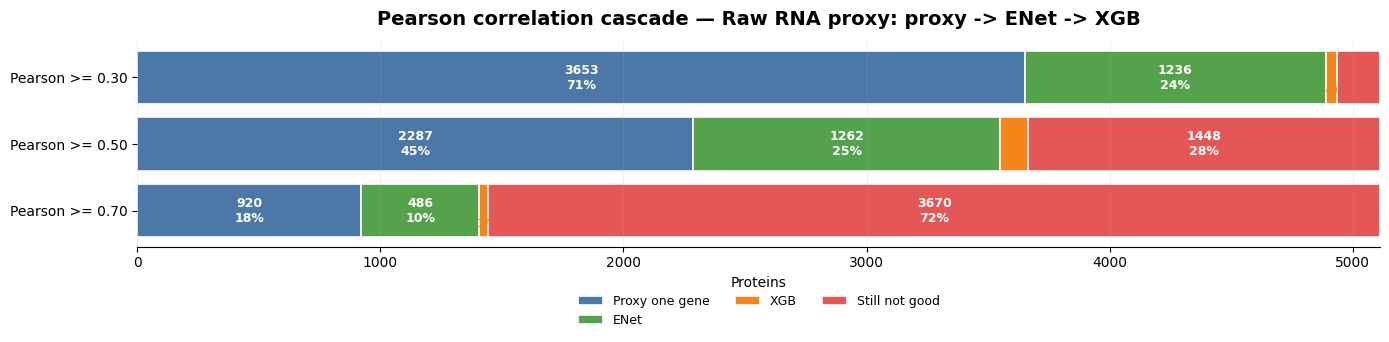

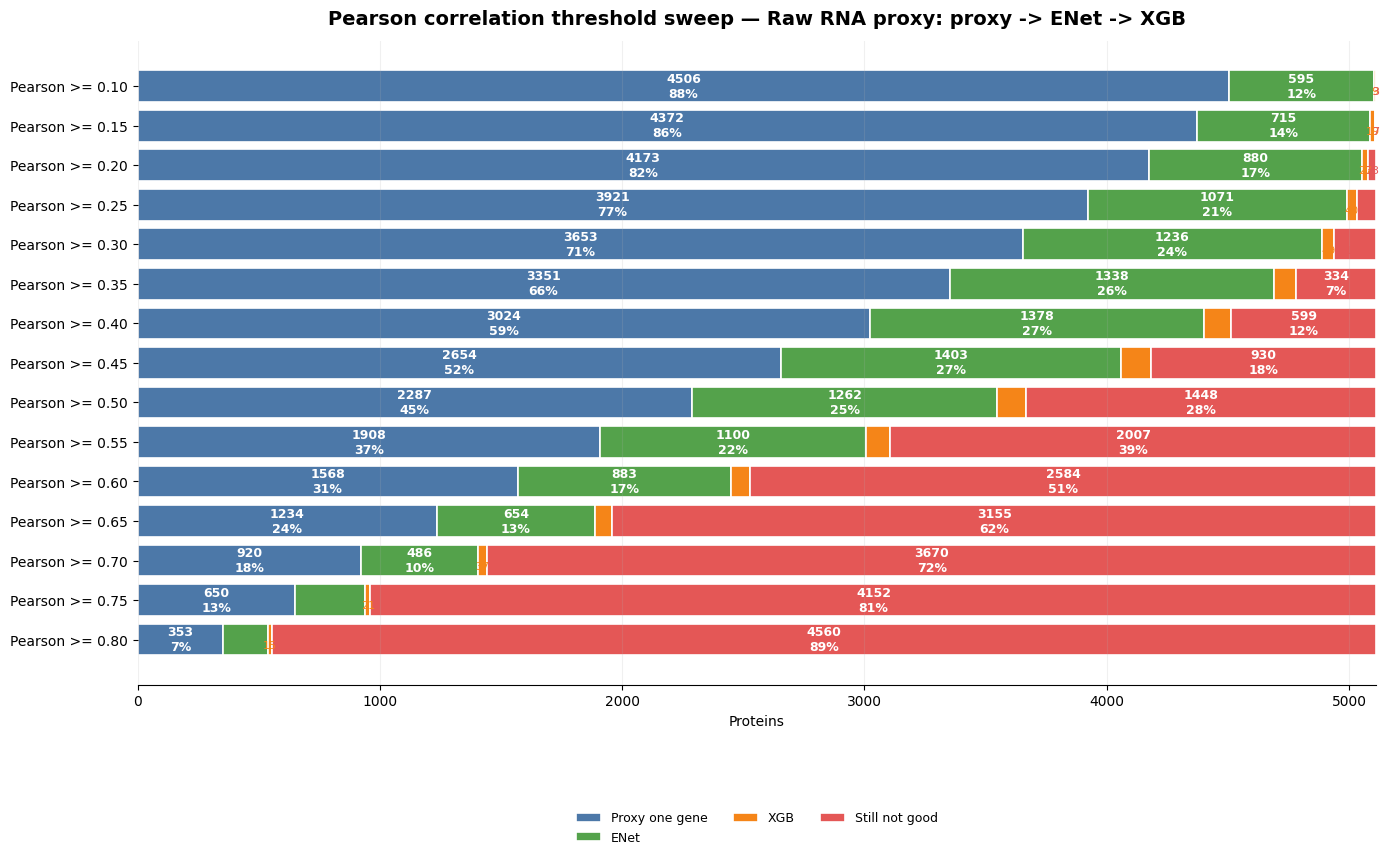


[raw] Cosine similarity main cascade


stage,Proxy one gene,ENet,XGB,Still not good
threshold,,,,
0.3,468,4409,66,170
0.5,67,3511,118,1417
0.7,0,1396,32,3685


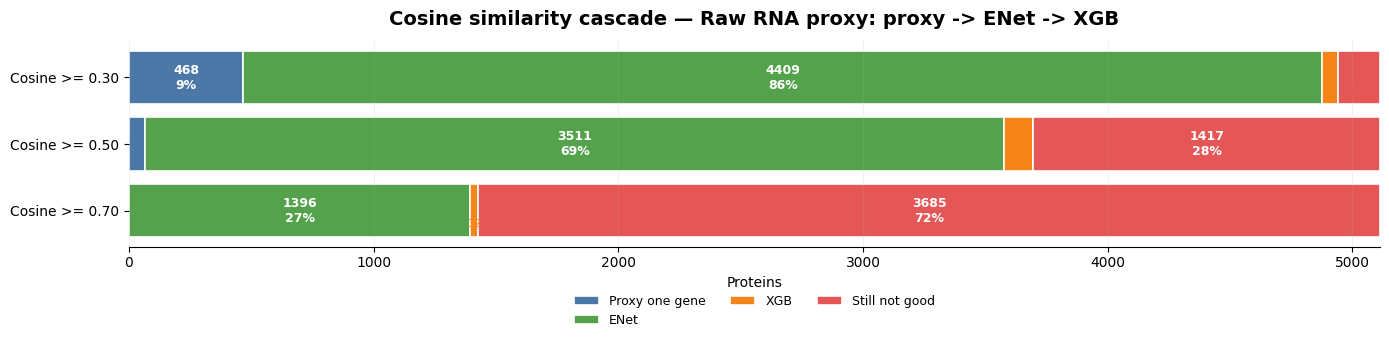

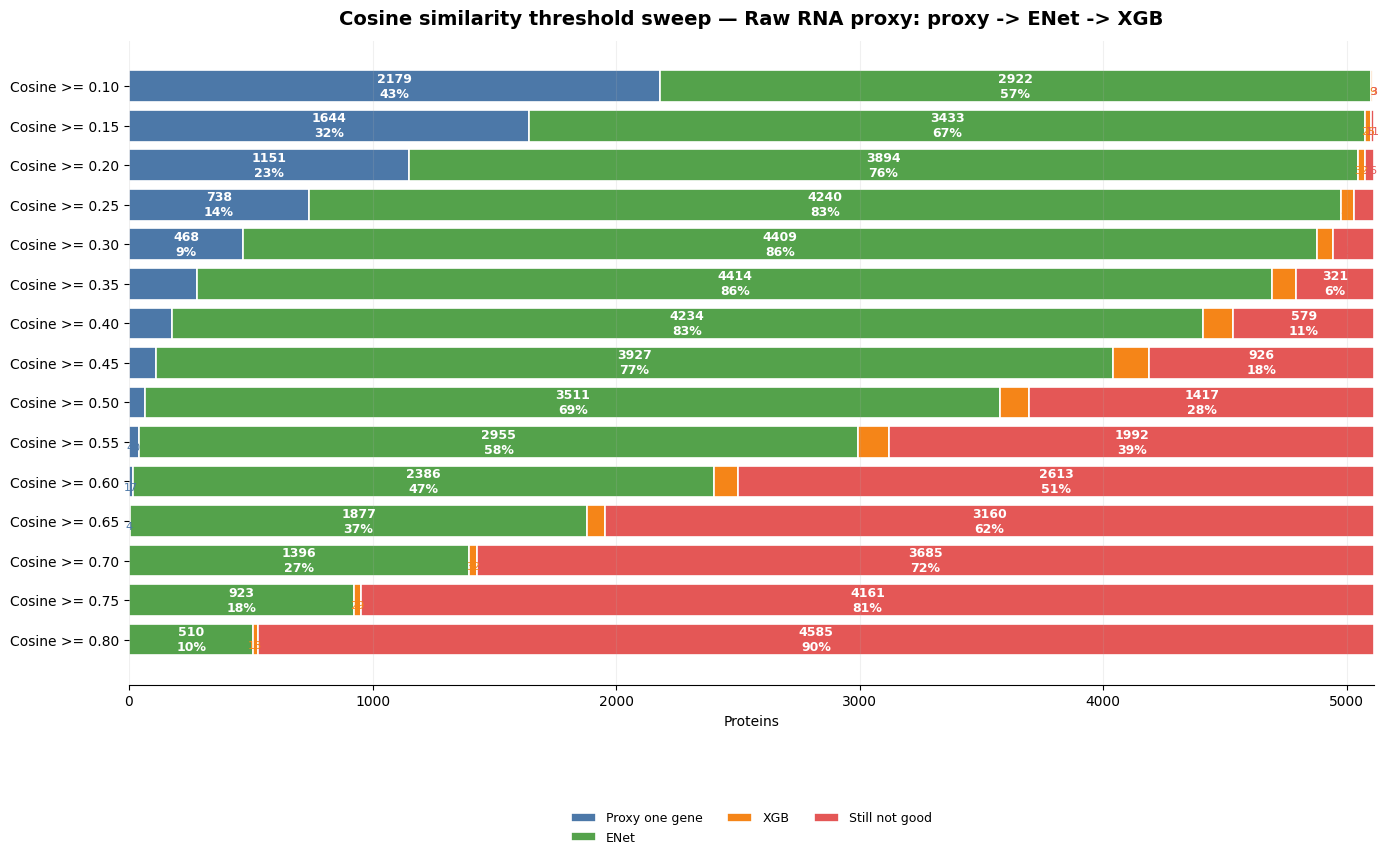


[raw] MSE main cascade


stage,Proxy one gene,ENet,XGB,Still not good
threshold,,,,
0.3,0,3231,58,1824
0.5,1,4523,17,572
0.7,5,4881,9,218


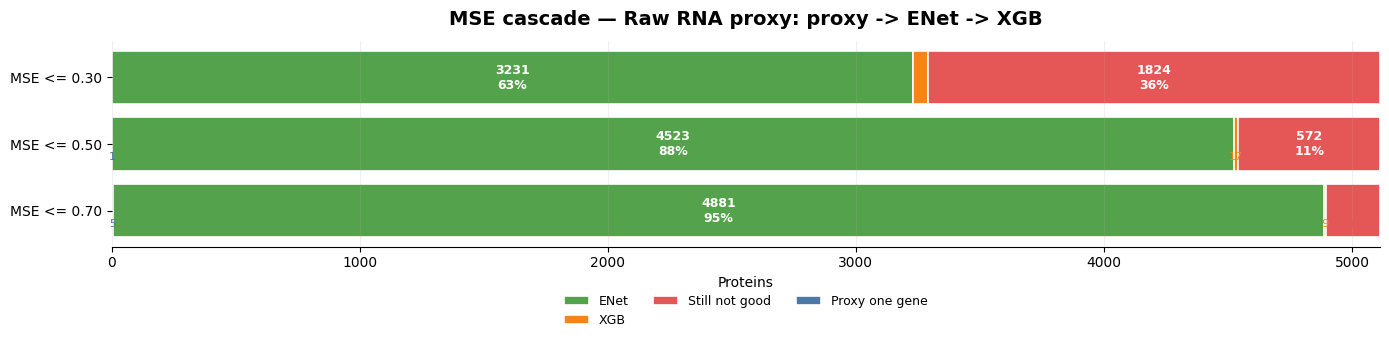

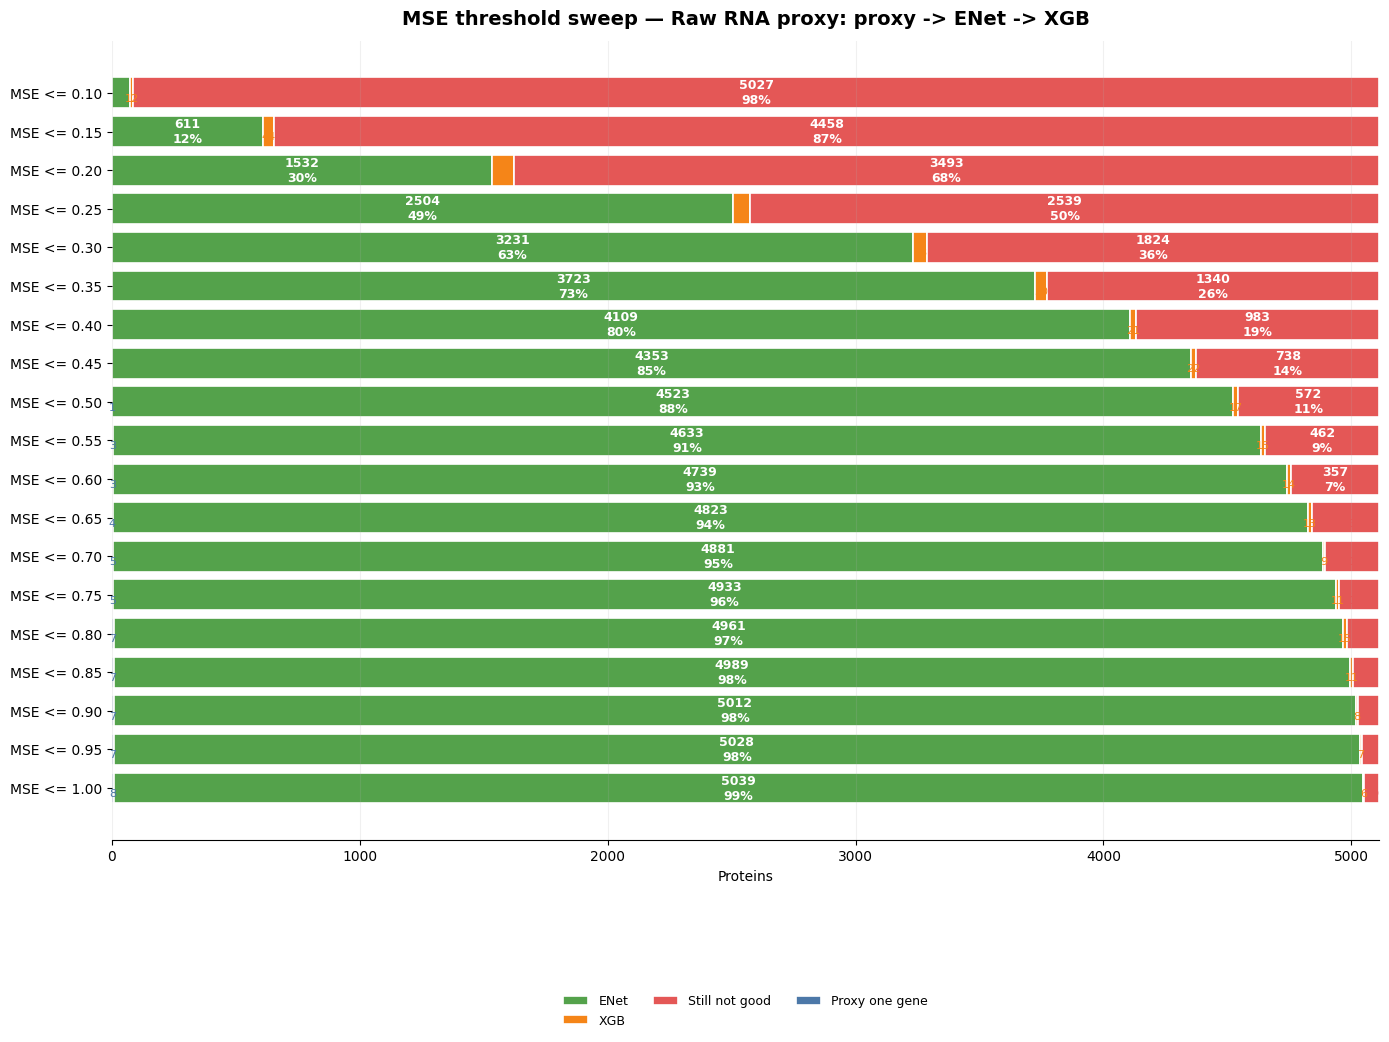


[train_zscore] Pearson correlation main cascade


stage,Proxy one gene,ENet,XGB,Still not good
threshold,,,,
0.3,3653,1236,49,175
0.5,2287,1262,116,1448
0.7,920,486,37,3670


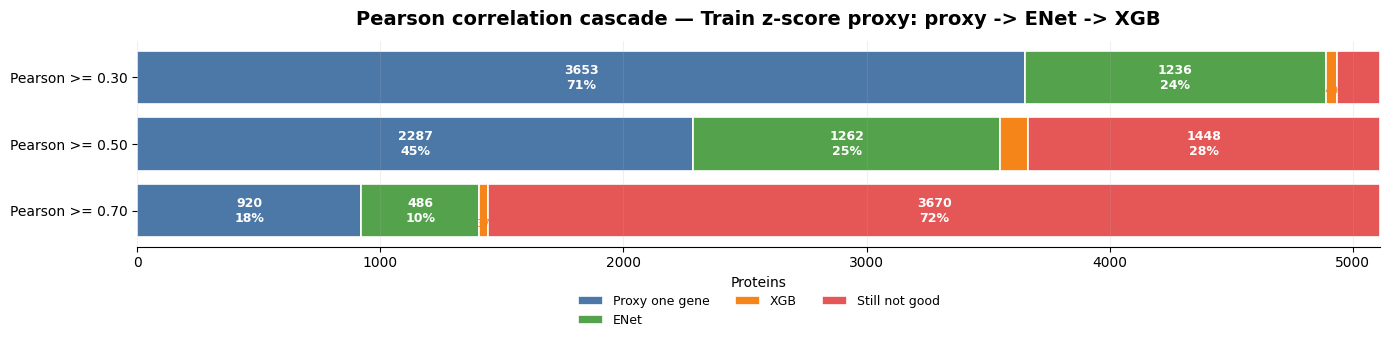

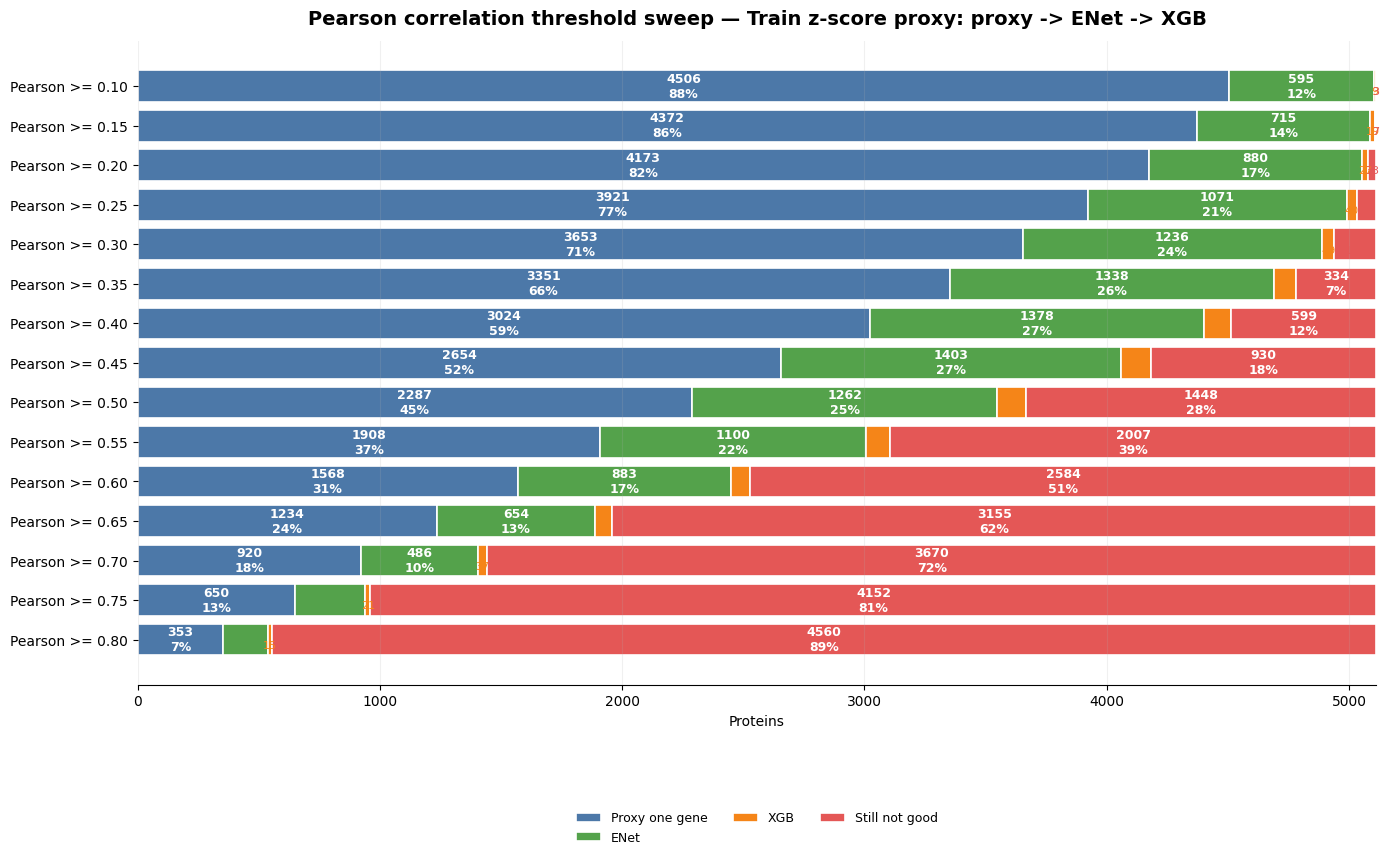


[train_zscore] Cosine similarity main cascade


stage,Proxy one gene,ENet,XGB,Still not good
threshold,,,,
0.3,3682,1239,50,142
0.5,2306,1333,106,1368
0.7,924,497,32,3660


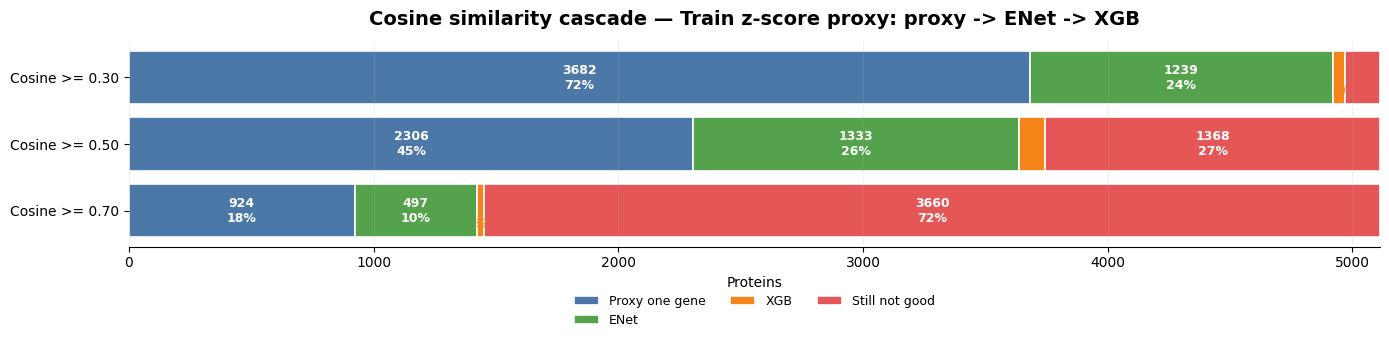

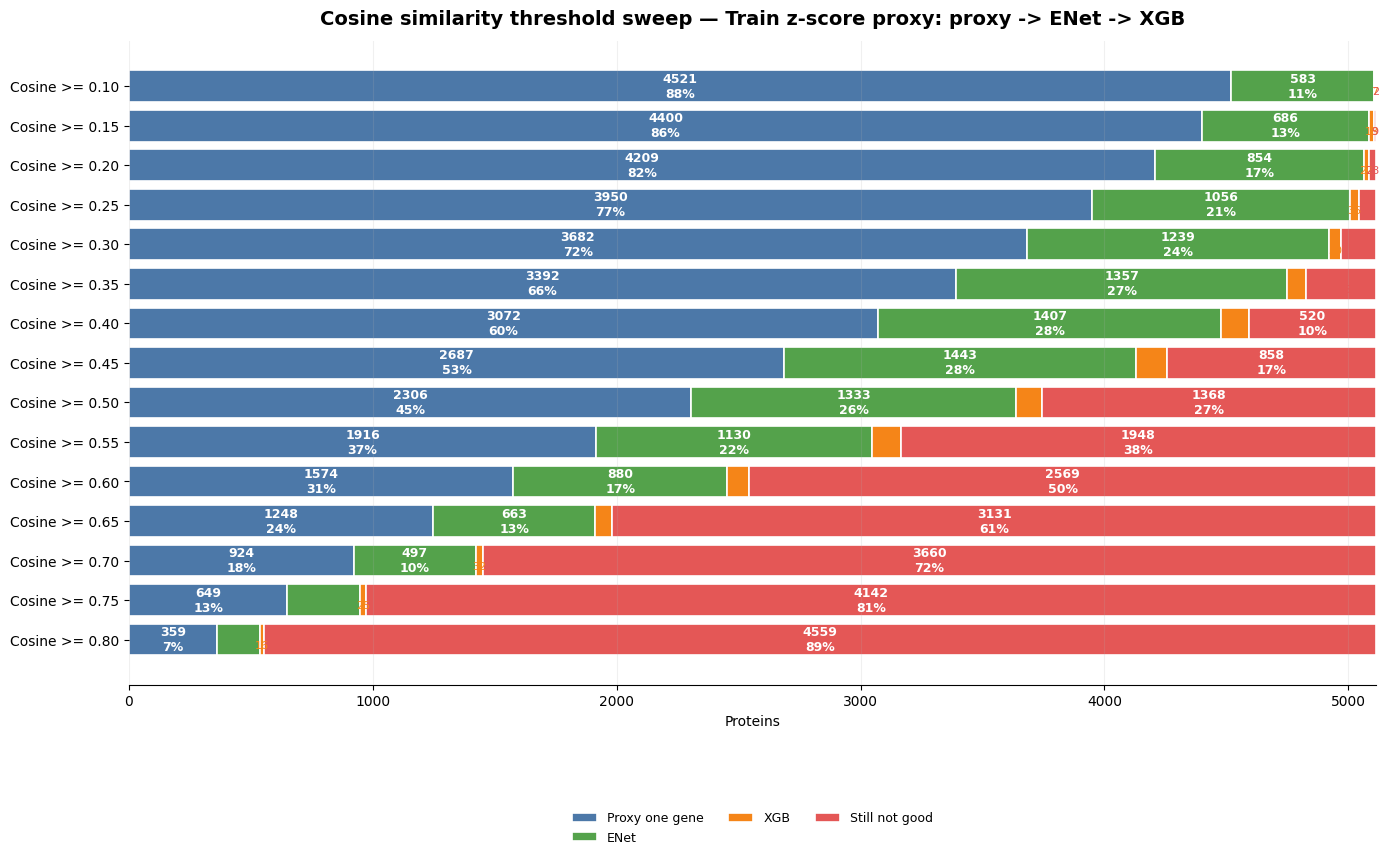


[train_zscore] MSE main cascade


stage,Proxy one gene,ENet,XGB,Still not good
threshold,,,,
0.3,1287,1954,57,1815
0.5,3320,1215,17,561
0.7,4190,709,7,207


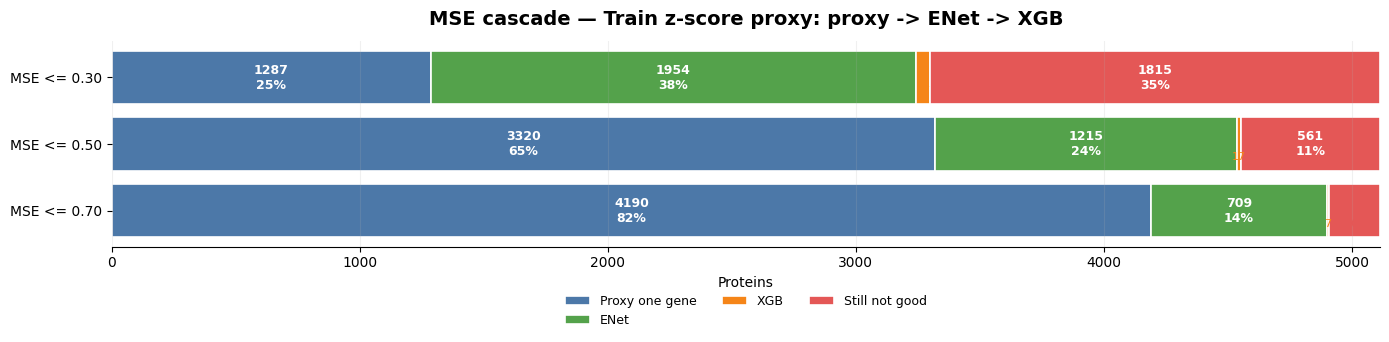

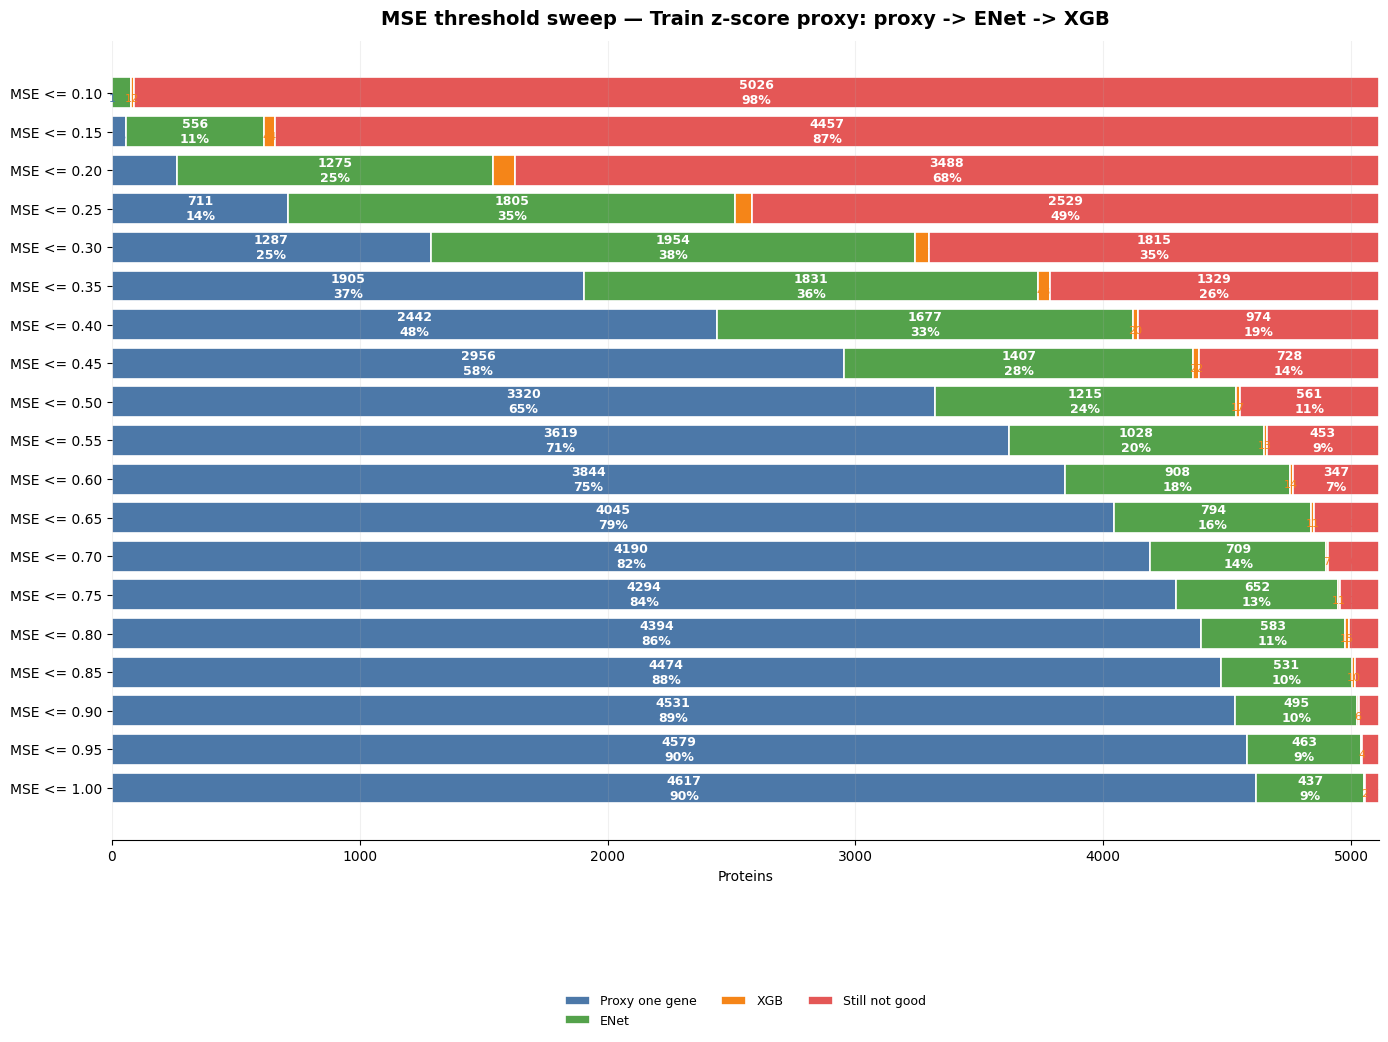


[train_linear] Pearson correlation main cascade


stage,Proxy one gene,ENet,XGB,Still not good
threshold,,,,
0.3,3652,1236,49,176
0.5,2287,1262,116,1448
0.7,920,486,37,3670


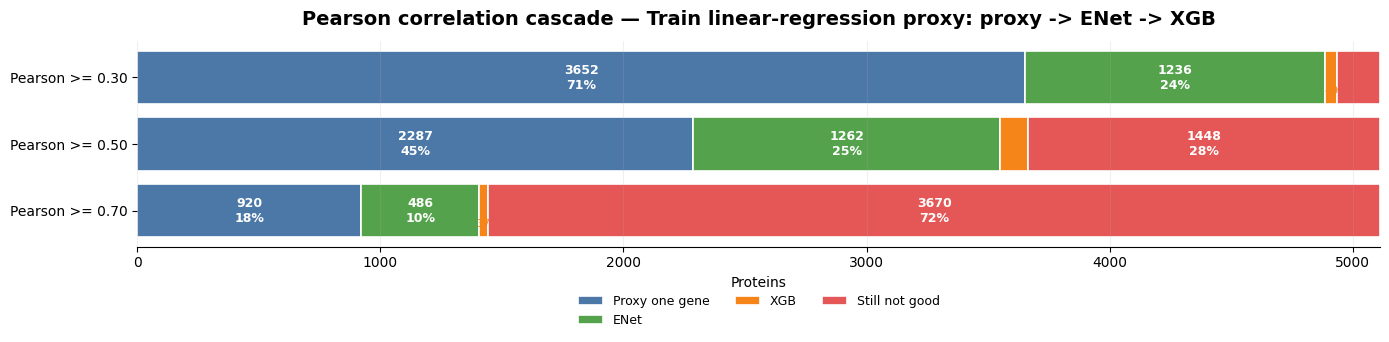

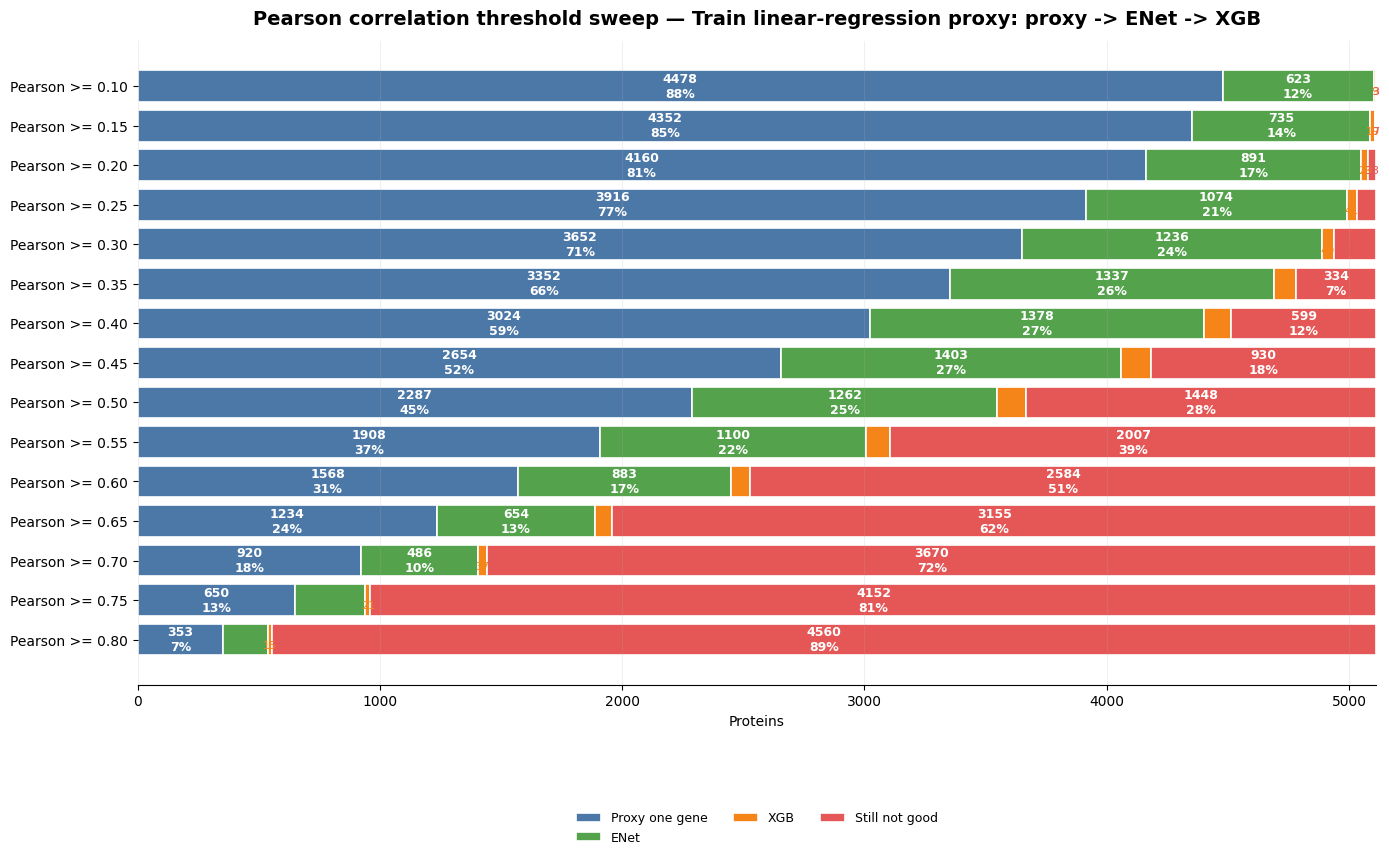


[train_linear] Cosine similarity main cascade


stage,Proxy one gene,ENet,XGB,Still not good
threshold,,,,
0.3,3732,1189,49,143
0.5,2318,1324,106,1365
0.7,922,498,32,3661


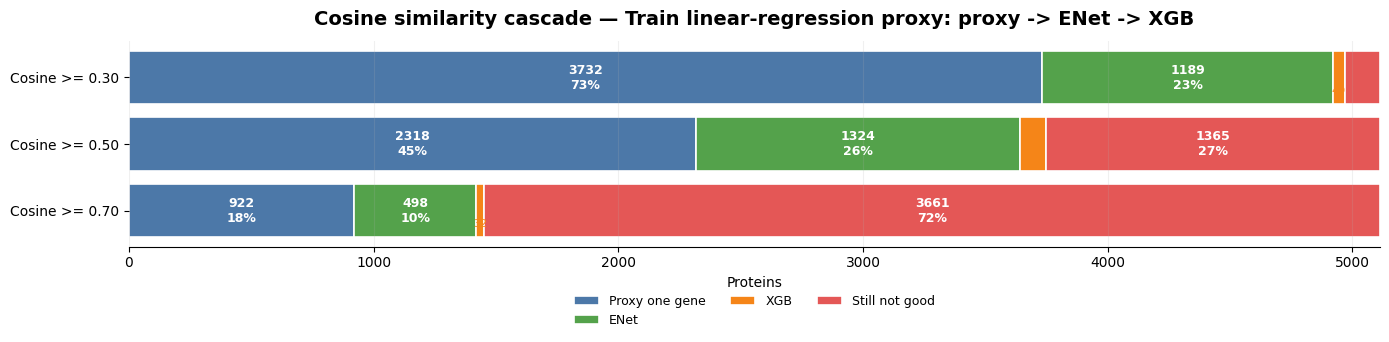

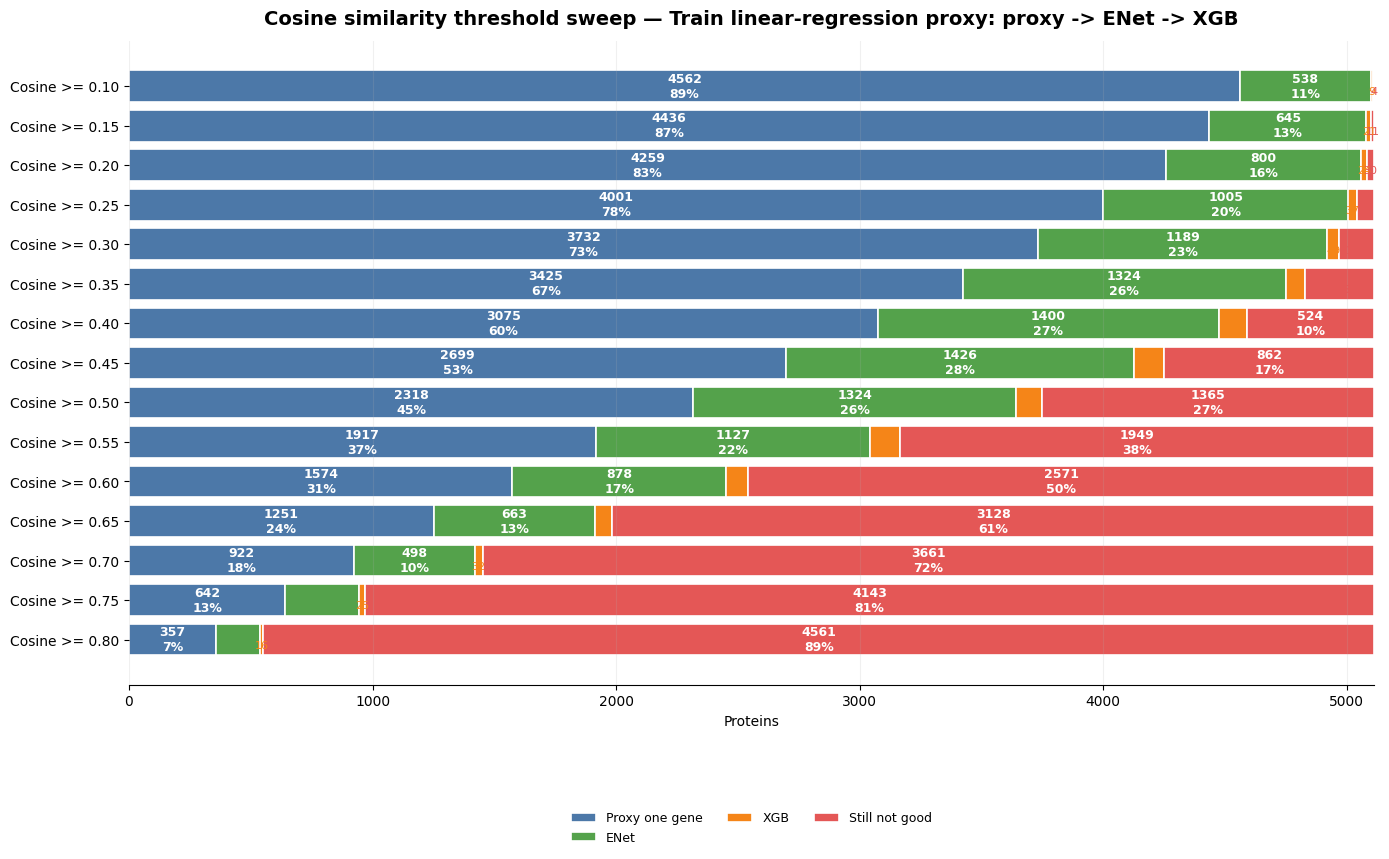


[train_linear] MSE main cascade


stage,Proxy one gene,ENet,XGB,Still not good
threshold,,,,
0.3,2645,633,54,1781
0.5,4079,469,17,548
0.7,4536,368,6,203


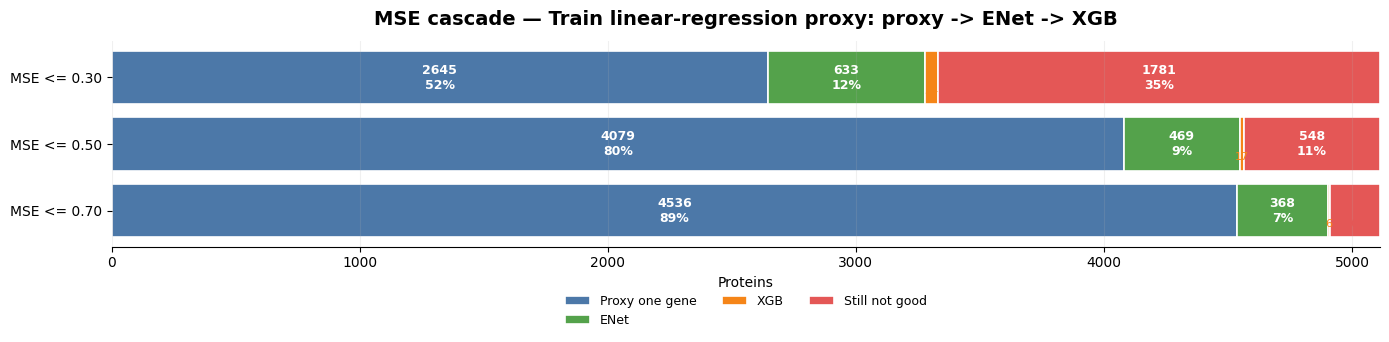

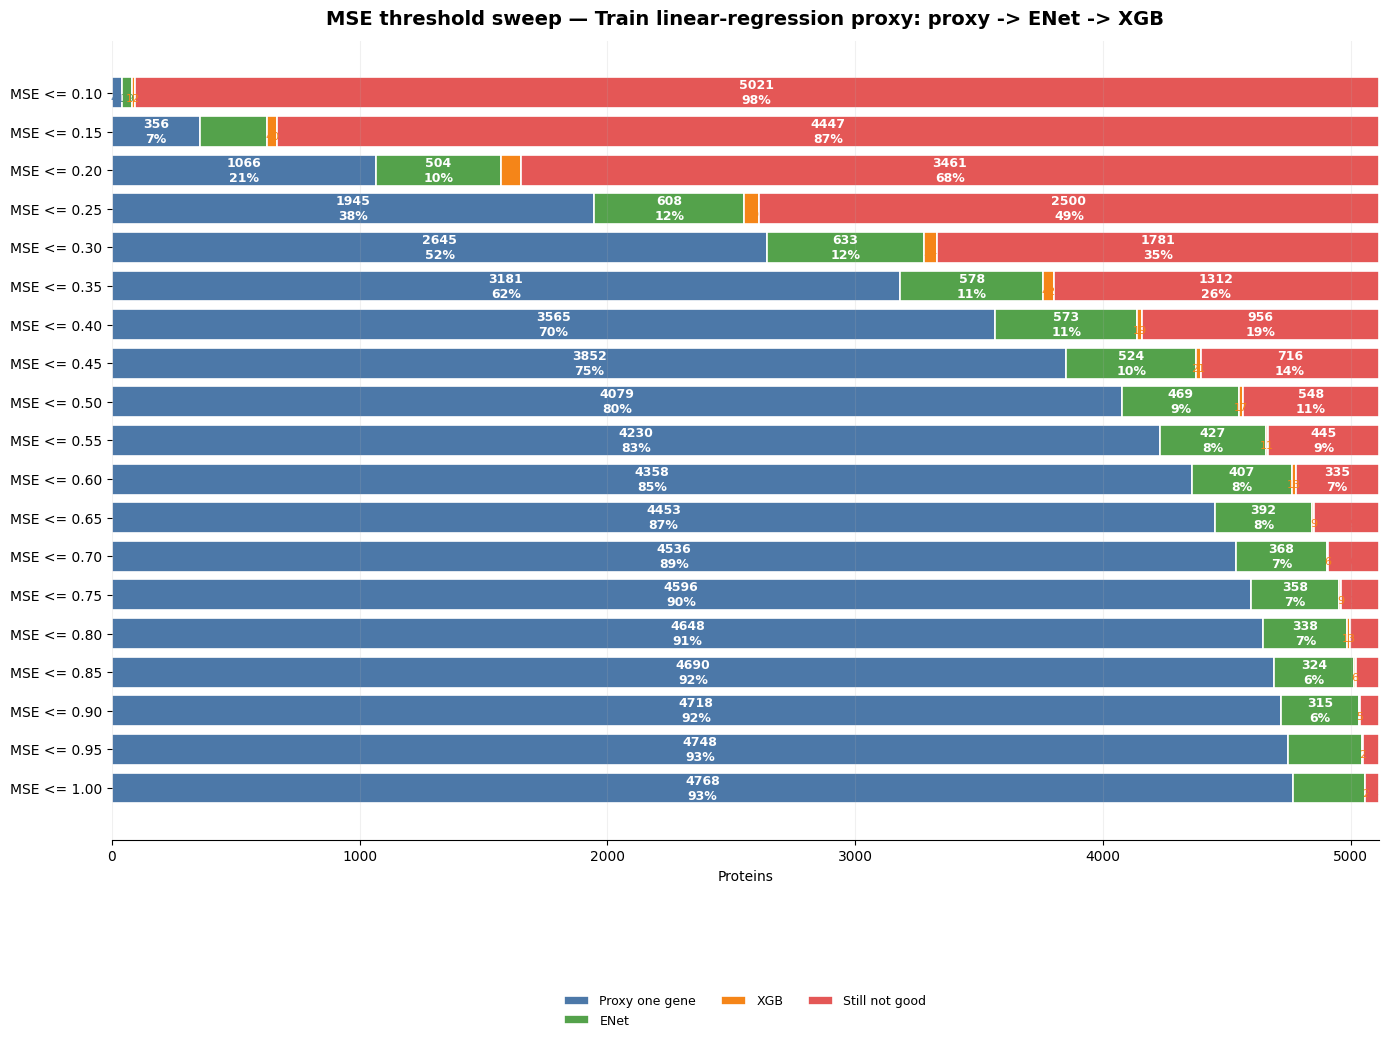

In [9]:
def run_base_analysis_for_mode(mode):
    set_output_context(mode)
    mode_label = PROXY_MODE_CONFIG[mode]["label"]
    mode_results = all_results_by_mode[mode]
    out = {}

    for metric_name, cfg in METRIC_CONFIG.items():
        proxy_best = best_family_from_results(
            mode_results,
            cfg["column"],
            "proxy",
            cfg["higher"],
        )
        enet_best = model_best[metric_name]["enet"]
        xgb_best = model_best[metric_name]["xgb"]

        def cascade_at(threshold):
            return procedural_metric_cascade(
                threshold,
                metric_col=cfg["column"],
                higher=cfg["higher"],
                proxy_best=proxy_best,
                enet_best=enet_best,
                xgb_best=xgb_best,
            )

        main_assignments = pd.concat(
            [cascade_at(thr) for thr in cfg["main_thresholds"]],
            ignore_index=True,
        )
        main_summary = summarize_assignments(main_assignments, order=CASCADE_ORDER_BASE)

        sweep_assignments = pd.concat(
            [cascade_at(thr) for thr in cfg["sweep_thresholds"]],
            ignore_index=True,
        )
        sweep_summary = summarize_assignments(sweep_assignments, order=CASCADE_ORDER_BASE)

        print(f"\n[{mode}] {cfg['title']} main cascade")
        display(
            main_summary
            .pivot_table(
                index="threshold",
                columns="stage",
                values="proteins",
                fill_value=0,
                aggfunc="sum",
            )
            .reindex(columns=CASCADE_ORDER_BASE)
        )

        plot_stacked_partition_rows(
            main_summary,
            title=f"{cfg['title']} cascade — {mode_label}: proxy -> ENet -> XGB",
            order=CASCADE_ORDER_BASE,
            save_name=f"{metric_name}_cascade_030_050_070.png",
            row_label_func=cfg["row_label"],
        )

        plot_stacked_partition_rows(
            sweep_summary,
            title=f"{cfg['title']} threshold sweep — {mode_label}: proxy -> ENet -> XGB",
            order=CASCADE_ORDER_BASE,
            save_name=f"{metric_name}_threshold_sweep.png",
            figsize=(14, max(5, 0.45 * len(cfg["sweep_thresholds"]) + 2.0)),
            row_label_func=cfg["row_label"],
        )

        out[metric_name] = {
            "proxy_best": proxy_best,
            "main_assignments": main_assignments,
            "main_summary": main_summary,
            "sweep_assignments": sweep_assignments,
            "sweep_summary": sweep_summary,
        }

    return out


analysis_results = {
    mode: run_base_analysis_for_mode(mode)
    for mode in PROXY_MODES_TO_RUN
}

## 10. Compare proxy modes directly

The three original notebooks discussed scale mismatch separately. Here the comparison is made in one place using the same proteins and split. Pearson association should be comparatively insensitive to positive affine rescaling, while cosine similarity and MSE can change substantially when predictions are moved onto the protein scale.

In [10]:
def distribution_diagnostics(name, df):
    arr = np.asarray(df, dtype=float).ravel()
    arr = arr[np.isfinite(arr)]
    return {
        "matrix": name,
        "n_values": int(arr.size),
        "min": float(np.min(arr)),
        "p01": float(np.quantile(arr, 0.01)),
        "median": float(np.median(arr)),
        "mean": float(np.mean(arr)),
        "p99": float(np.quantile(arr, 0.99)),
        "max": float(np.max(arr)),
        "fraction_negative": float(np.mean(arr < 0)),
        "fraction_zero": float(np.mean(arr == 0)),
    }


xy_distribution_diagnostics = pd.DataFrame([
    distribution_diagnostics("Transcriptomics X", X),
    distribution_diagnostics("Proteomics Y", Y),
])

display(xy_distribution_diagnostics)

proxy_metric_diagnostics = (
    proxy_results_all
    .groupby(["proxy_mode", "proxy_mode_label", "normalization"], dropna=False)
    .agg(
        proteins=("protein", "nunique"),
        median_proxy_corr_train=("same_gene_corr_train", "median"),
        median_test_pearson=("test_pearson_corr", "median"),
        median_test_cosine=("test_cosine_similarity", "median"),
        median_test_mse=("test_mse", "median"),
    )
    .reset_index()
)

display(proxy_metric_diagnostics)

comparison_rows = []
for mode in PROXY_MODES_TO_RUN:
    for metric_name in METRIC_CONFIG:
        tmp = analysis_results[mode][metric_name]["main_summary"].copy()
        tmp["proxy_mode"] = mode
        tmp["metric_name"] = metric_name
        comparison_rows.append(tmp)

main_cascade_comparison = pd.concat(comparison_rows, ignore_index=True)
display(main_cascade_comparison)

,matrix,n_values,min,p01,median,mean,p99,max,fraction_negative,fraction_zero
0,Transcriptomics X,8344566,0.000000,0.000000,2.130931,2.592417,9.016056,17.253967,0.000000,0.116077
1,Proteomics Y,1886697,-16.951352,-2.118034,-0.023866,-0.021529,2.161464,7.722932,0.515855,0.000000


,proxy_mode,proxy_mode_label,normalization,proteins,median_proxy_corr_train,median_test_pearson,median_test_cosine,median_test_mse
0,raw,Raw RNA proxy,raw_gene_value,4843,0.468147,0.482946,0.078530,25.463506
1,train_linear,Train linear-regression proxy,train_linear_regression,4843,0.468147,0.482946,0.484671,0.281958
2,train_zscore,Train z-score proxy,train_zscore_gene_to_protein_scale,4843,0.468147,0.482946,0.484952,0.397813


,threshold,stage,proteins,total_proteins,percent,proxy_mode,metric_name
0,0.3,Proxy one gene,3653,5113,71.445335,raw,pearson
1,0.3,ENet,1236,5113,24.173675,raw,pearson
2,0.3,XGB,49,5113,0.958341,raw,pearson
3,0.3,Still not good,175,5113,3.422648,raw,pearson
4,0.5,Proxy one gene,2287,5113,44.729122,raw,pearson
...,...,...,...,...,...,...,...
101,0.5,Still not good,548,5113,10.717778,train_linear,mse
102,0.7,Proxy one gene,4536,5113,88.715040,train_linear,mse
103,0.7,ENet,368,5113,7.197340,train_linear,mse
104,0.7,XGB,6,5113,0.117348,train_linear,mse


## 11. Load scTranslator predictions once

scTranslator predictions do not depend on proxy normalization, so they are loaded and evaluated only once on the common H5 test split.

In [11]:
sctranslator_pred_dfs = load_sctranslator_prediction_tables()
sctranslator_results = evaluate_sctranslator_predictions(
    sctranslator_pred_dfs,
    gt=GT_scaled,
    eval_samples=test_samples,
)

sctranslator_results = add_family_group(sctranslator_results)

print("scTranslator result rows:", len(sctranslator_results))
if len(sctranslator_results):
    display(
        sctranslator_results.groupby("run_label")
        .agg(
            proteins=("protein", "nunique"),
            pearson_median=("test_pearson_corr", "median"),
            pearson_mean=("test_pearson_corr", "mean"),
            cosine_median=("test_cosine_similarity", "median"),
            cosine_mean=("test_cosine_similarity", "mean"),
            mse_median=("test_mse", "median"),
            mse_mean=("test_mse", "mean"),
        )
        .sort_values("pearson_median", ascending=False)
    )
    display(sctranslator_results.head())
else:
    print("No scTranslator predictions were loaded. The final rescue plots below will be skipped.")

# Keep moved utility functions synchronized with notebook variables.
try:
    uc.set_module_globals(globals())
except NameError:
    pass

scTranslator result rows: 15339


,proteins,pearson_median,pearson_mean,cosine_median,cosine_mean,mse_median,mse_mean
run_label,,,,,,,
scTranslator 160K,5113,-0.004724,-0.007454,0.008041,0.008173,13198.581632,14467.754852
scTranslator 2M,5113,-0.005029,-0.003427,0.000828,-0.000881,11707.122961,38907.767845
scTranslator 10K,5113,-0.012217,-0.011571,-0.024273,-0.024392,0.674487,0.868456


,protein,run_label,model_family,family_group,sc_size,source_folder,test_mse,test_pearson_corr,test_cosine_similarity,n_test_used,train_n,test_n,split_hash,h5_path
0,A2M,scTranslator 2M,sctranslator,sctranslator,2M,scTranslator npz,1929.069576,-0.188503,0.354583,74,NaN,74,d0750f1c44a2,
1,AAAS,scTranslator 2M,sctranslator,sctranslator,2M,scTranslator npz,2553.709484,-0.005944,-0.149269,74,NaN,74,d0750f1c44a2,
2,AACS,scTranslator 2M,sctranslator,sctranslator,2M,scTranslator npz,47197.703064,0.012968,0.062528,74,NaN,74,d0750f1c44a2,
3,AAGAB,scTranslator 2M,sctranslator,sctranslator,2M,scTranslator npz,616.272881,0.181502,0.032709,74,NaN,74,d0750f1c44a2,
4,AAK1,scTranslator 2M,sctranslator,sctranslator,2M,scTranslator npz,87522.725488,0.310178,-0.129605,74,NaN,74,d0750f1c44a2,


## 12. Generic scTranslator final-rescue analysis

For each proxy mode and each metric, scTranslator is applied only to proteins that remain unresolved after proxy → ENet → XGB. The same generic rescue helper covers Pearson, cosine similarity, and MSE.


[raw] Pearson correlation with scTranslator final rescue


stage,Proxy one gene,ENet,XGB,scTranslator 2M,scTranslator 160K,scTranslator 10K,Still not good after scTranslator
threshold,,,,,,,
0.3,3653,1236,49,1,1,0,173
0.5,2287,1262,116,0,0,0,1448
0.7,920,486,37,0,0,0,3670


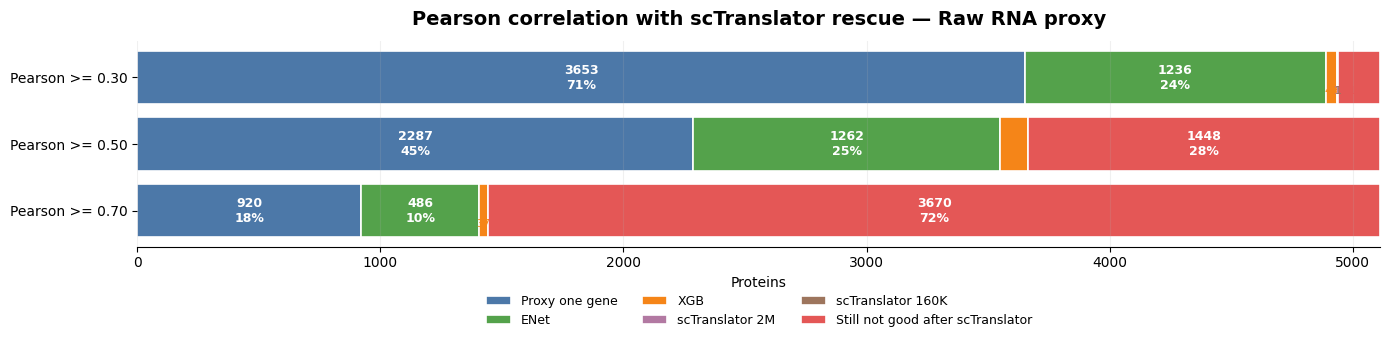

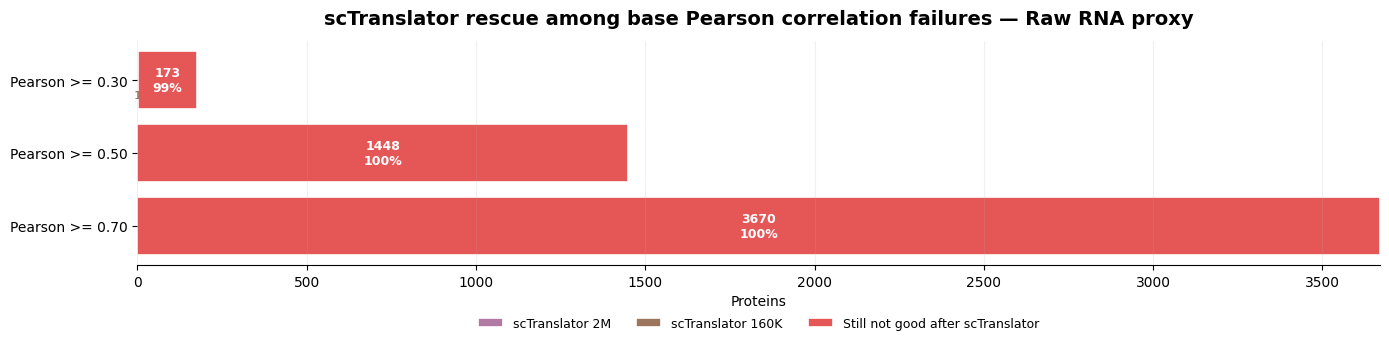


[raw] Cosine similarity with scTranslator final rescue


stage,Proxy one gene,ENet,XGB,scTranslator 2M,scTranslator 160K,scTranslator 10K,Still not good after scTranslator
threshold,,,,,,,
0.3,468,4409,66,0,1,0,169
0.5,67,3511,118,0,0,0,1417
0.7,0,1396,32,0,0,0,3685


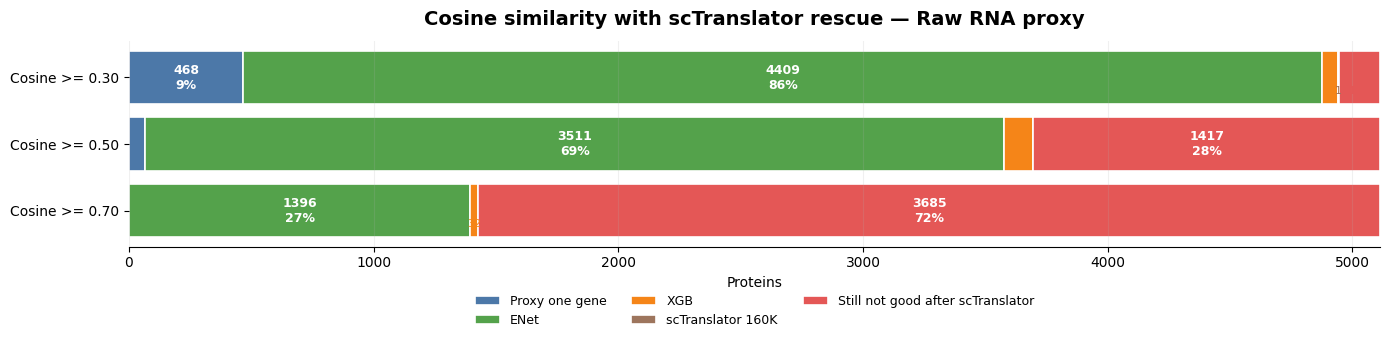

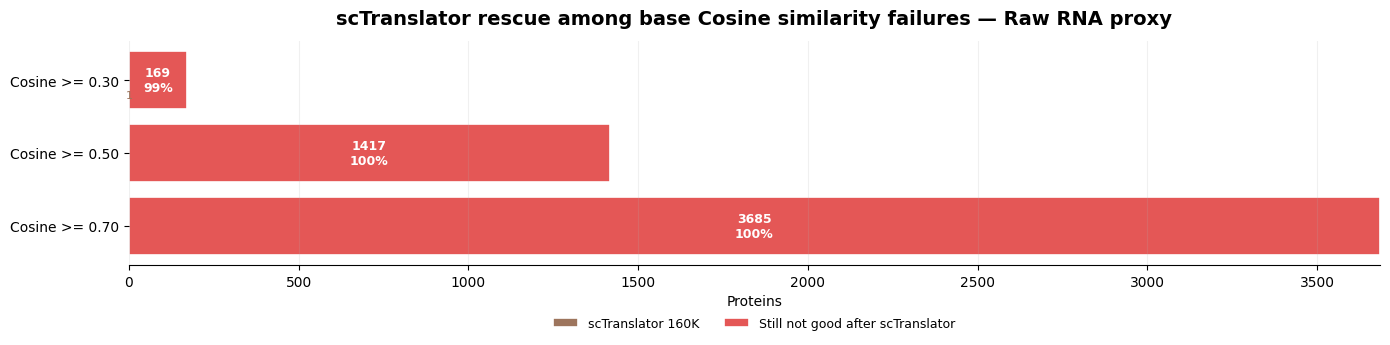


[raw] MSE with scTranslator final rescue


stage,Proxy one gene,ENet,XGB,scTranslator 2M,scTranslator 160K,scTranslator 10K,Still not good after scTranslator
threshold,,,,,,,
0.3,0,3231,58,0,0,0,1824
0.5,1,4523,17,0,0,0,572
0.7,5,4881,9,0,0,0,218


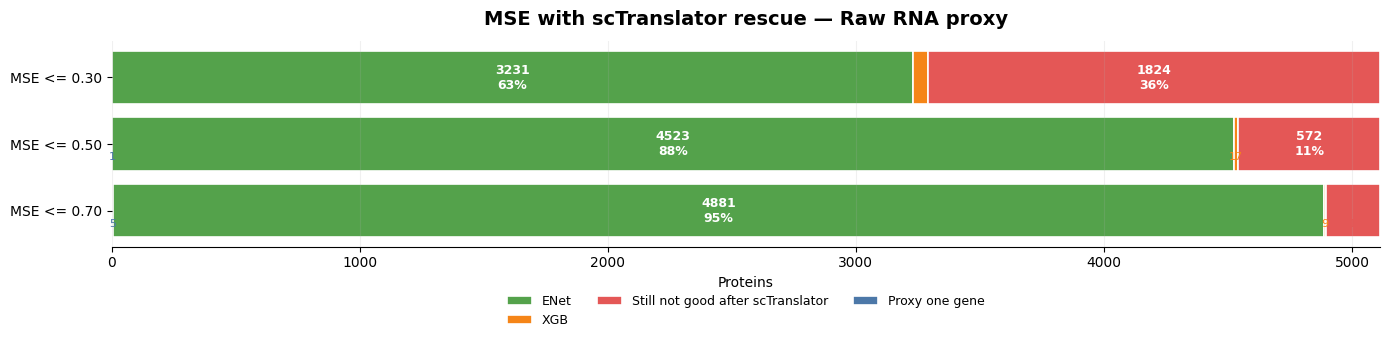

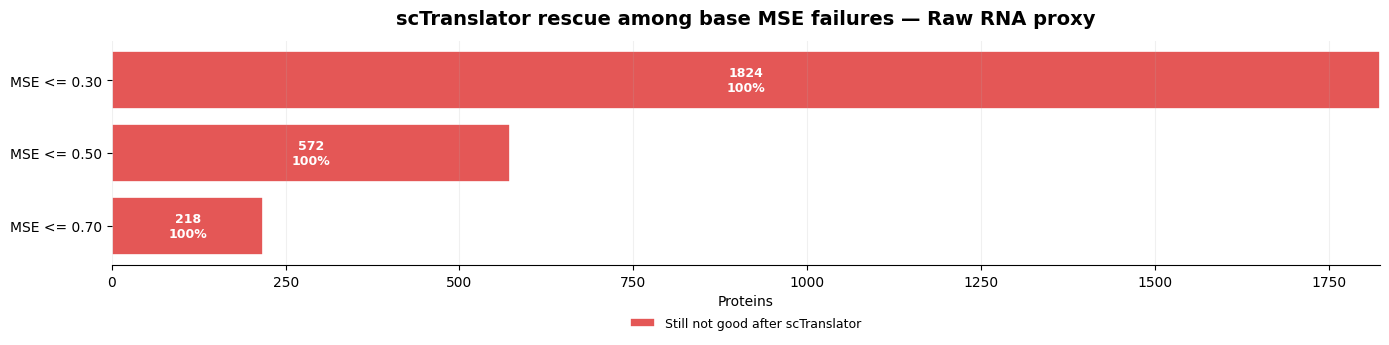


[train_zscore] Pearson correlation with scTranslator final rescue


stage,Proxy one gene,ENet,XGB,scTranslator 2M,scTranslator 160K,scTranslator 10K,Still not good after scTranslator
threshold,,,,,,,
0.3,3653,1236,49,1,1,0,173
0.5,2287,1262,116,0,0,0,1448
0.7,920,486,37,0,0,0,3670


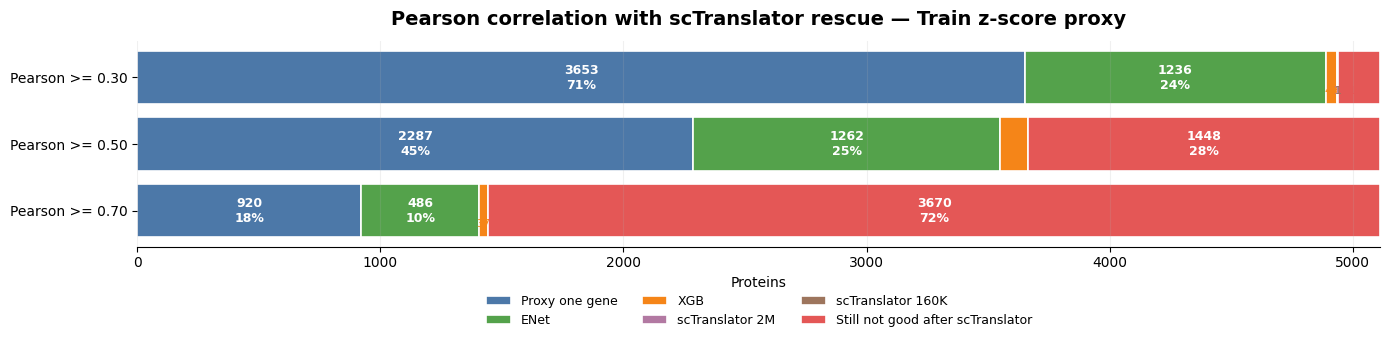

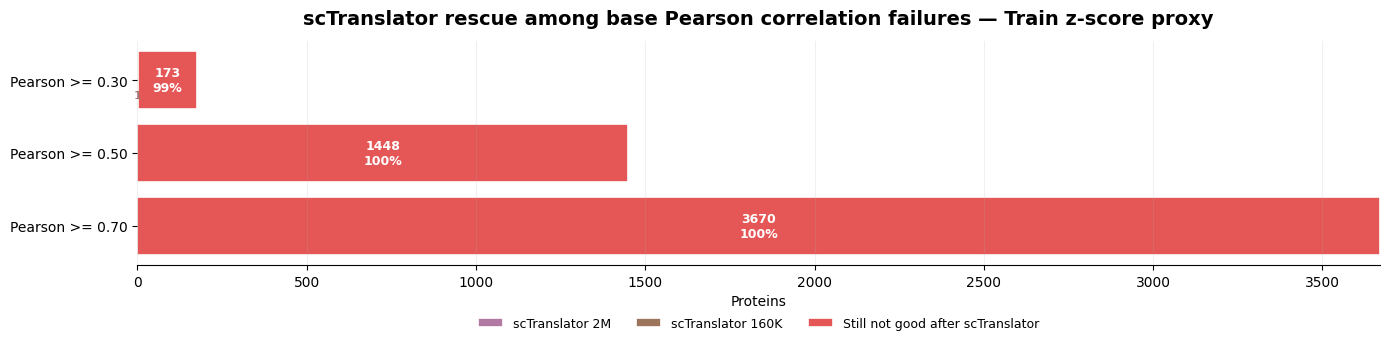


[train_zscore] Cosine similarity with scTranslator final rescue


stage,Proxy one gene,ENet,XGB,scTranslator 2M,scTranslator 160K,scTranslator 10K,Still not good after scTranslator
threshold,,,,,,,
0.3,3682,1239,50,0,1,0,141
0.5,2306,1333,106,0,0,0,1368
0.7,924,497,32,0,0,0,3660


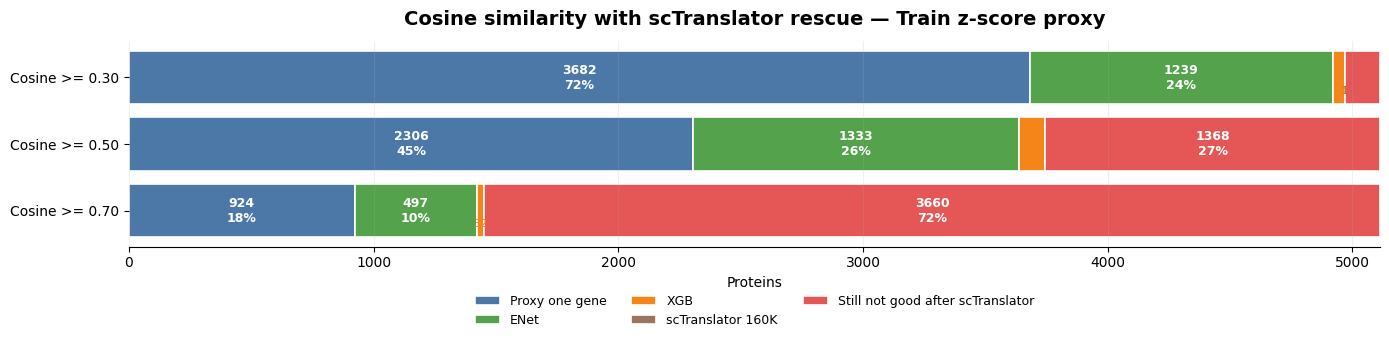

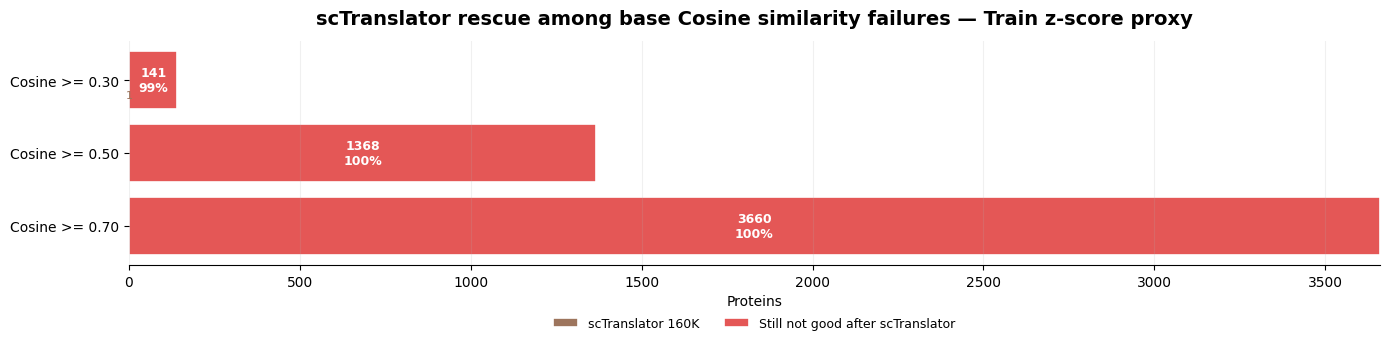


[train_zscore] MSE with scTranslator final rescue


stage,Proxy one gene,ENet,XGB,scTranslator 2M,scTranslator 160K,scTranslator 10K,Still not good after scTranslator
threshold,,,,,,,
0.3,1287,1954,57,0,0,0,1815
0.5,3320,1215,17,0,0,0,561
0.7,4190,709,7,0,0,0,207


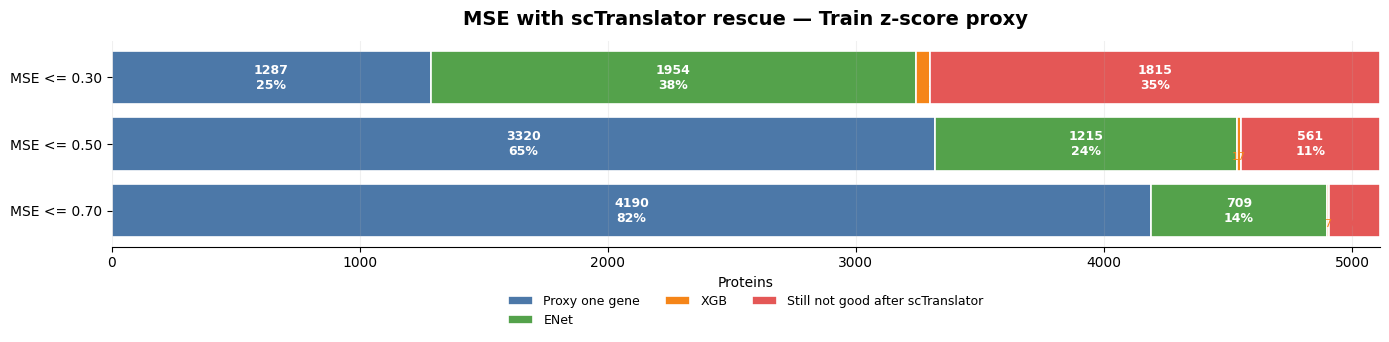

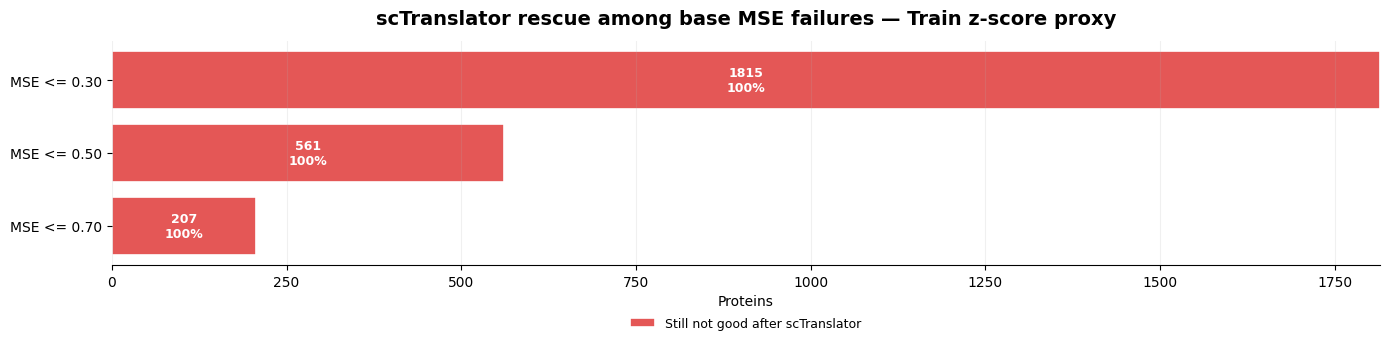


[train_linear] Pearson correlation with scTranslator final rescue


stage,Proxy one gene,ENet,XGB,scTranslator 2M,scTranslator 160K,scTranslator 10K,Still not good after scTranslator
threshold,,,,,,,
0.3,3652,1236,49,1,1,0,174
0.5,2287,1262,116,0,0,0,1448
0.7,920,486,37,0,0,0,3670


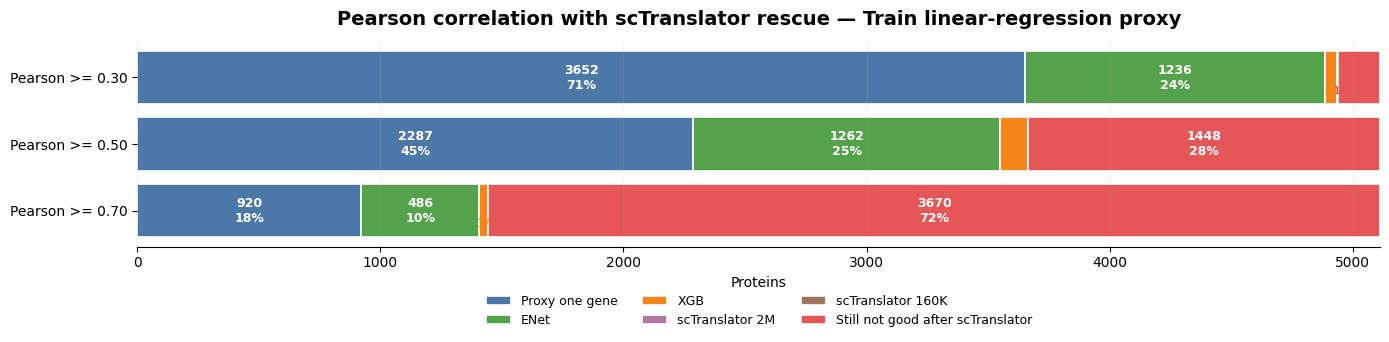

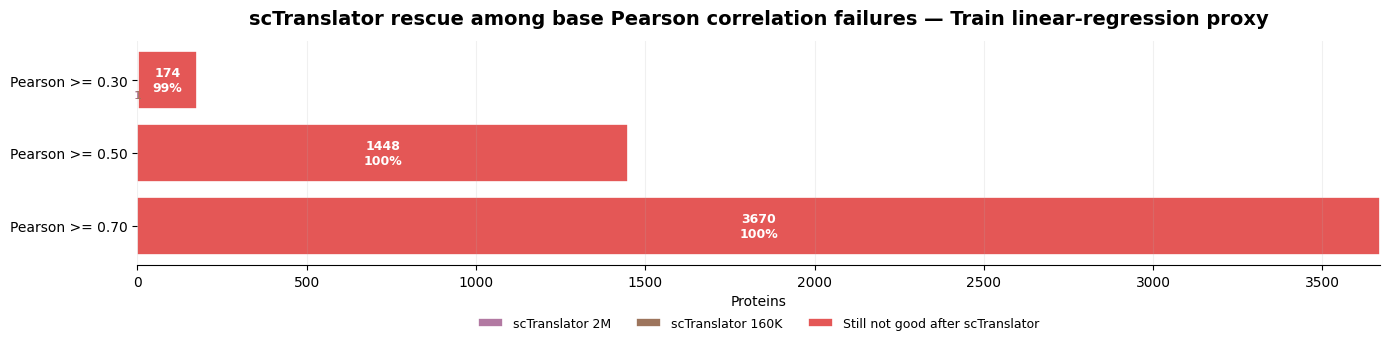


[train_linear] Cosine similarity with scTranslator final rescue


stage,Proxy one gene,ENet,XGB,scTranslator 2M,scTranslator 160K,scTranslator 10K,Still not good after scTranslator
threshold,,,,,,,
0.3,3732,1189,49,0,1,0,142
0.5,2318,1324,106,0,0,0,1365
0.7,922,498,32,0,0,0,3661


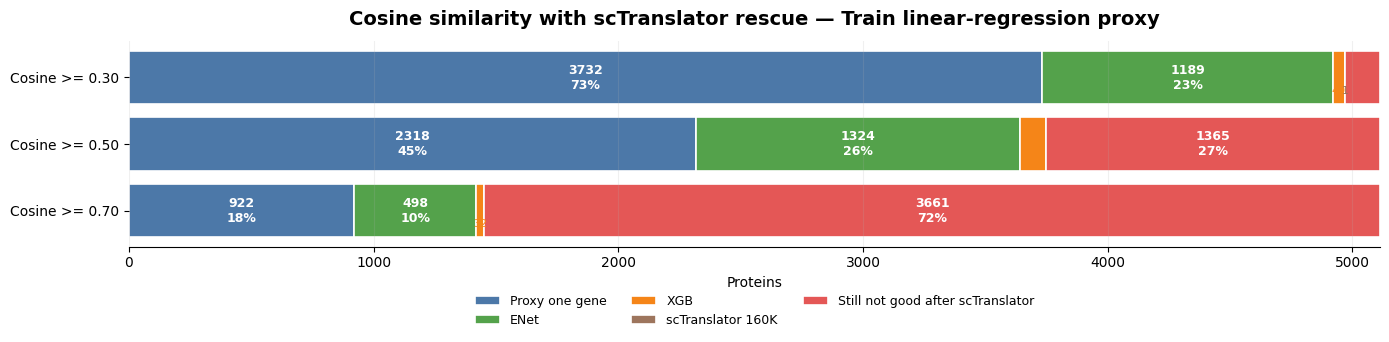

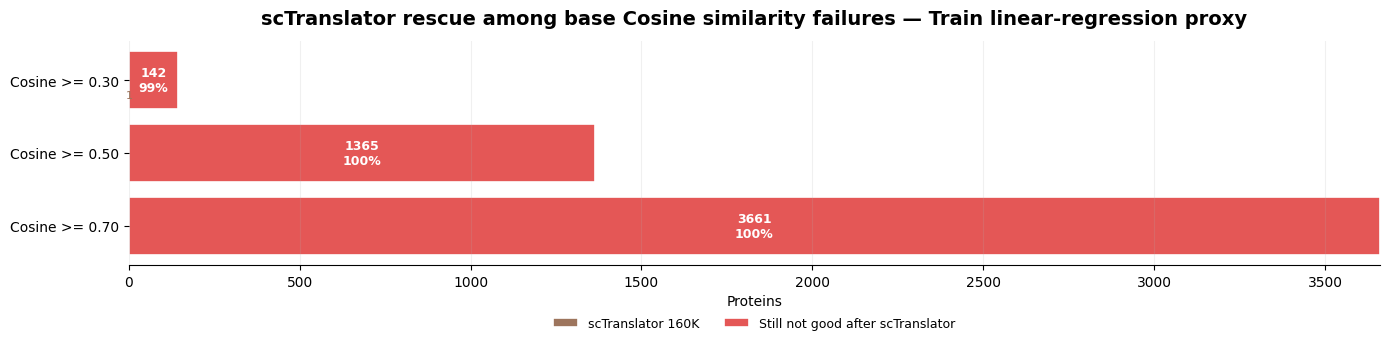


[train_linear] MSE with scTranslator final rescue


stage,Proxy one gene,ENet,XGB,scTranslator 2M,scTranslator 160K,scTranslator 10K,Still not good after scTranslator
threshold,,,,,,,
0.3,2645,633,54,0,0,0,1781
0.5,4079,469,17,0,0,0,548
0.7,4536,368,6,0,0,0,203


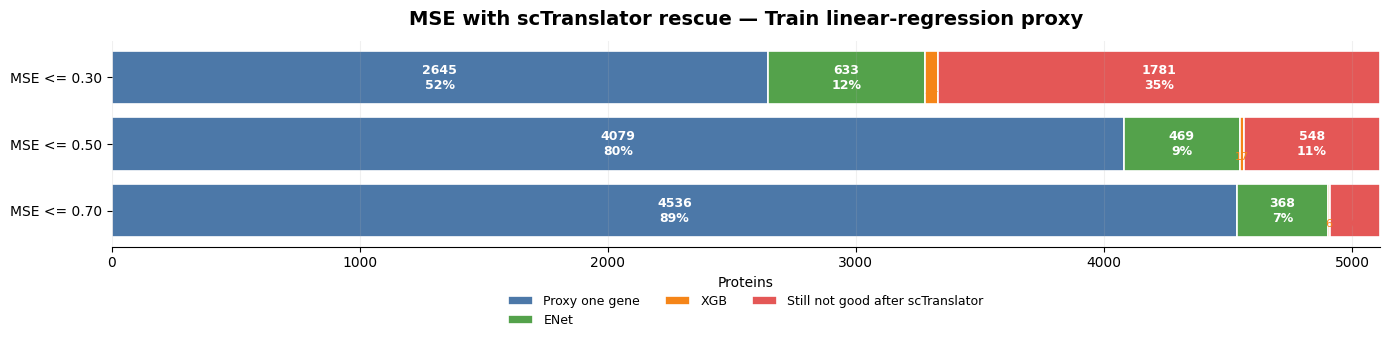

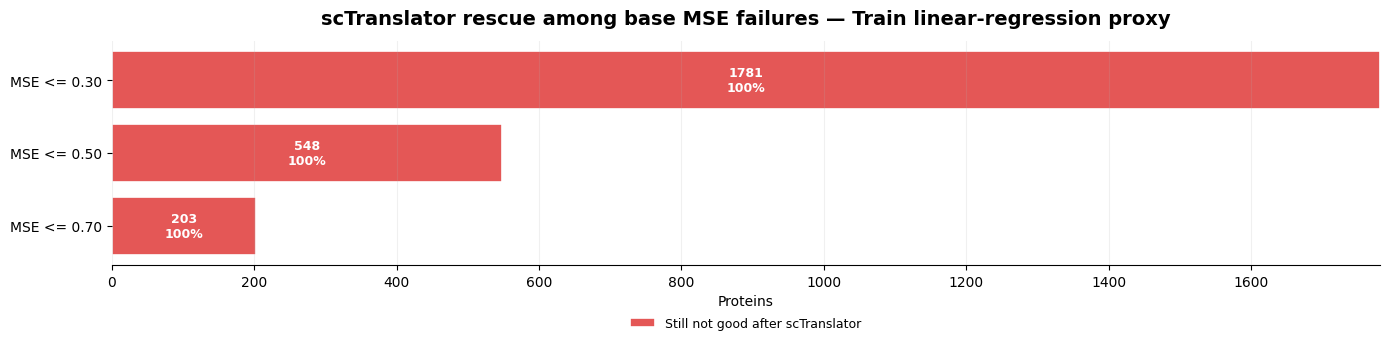

In [12]:
def sctranslator_stage_from_row(row):
    sc_size = row.get("sc_size", np.nan)
    if pd.notna(sc_size) and str(sc_size).strip():
        label = str(sc_size).replace("scTranslator ", "").strip()
    else:
        label = str(row.get("run_label", "")).replace("scTranslator ", "").strip()
    return f"scTranslator {label}" if label else "scTranslator"


def add_sctranslator_rescue(base_assignments, sctranslator_best, *, metric_col, higher):
    sc_idx = index_by_protein(sctranslator_best)
    full_rows = []
    rescue_rows = []

    for _, base_row in base_assignments.iterrows():
        out = base_row.to_dict()
        if str(base_row["stage"]) != "Still not good":
            full_rows.append(out)
            continue

        protein = str(base_row["protein"])
        threshold = float(base_row["threshold"])

        if protein in sc_idx.index:
            sc_row = sc_idx.loc[protein]
            value = sc_row.get(metric_col, np.nan)
            rescued = metric_is_good(value, threshold, higher)
            out.update({
                "stage": sctranslator_stage_from_row(sc_row) if rescued else "Still not good after scTranslator",
                "metric": value,
                metric_col: value,
                "run_label": sc_row.get("run_label", np.nan),
                "sc_size": sc_row.get("sc_size", np.nan),
            })
        else:
            out.update({
                "stage": "Still not good after scTranslator",
                metric_col: np.nan,
                "run_label": np.nan,
                "sc_size": np.nan,
            })

        full_rows.append(out)
        rescue_rows.append(out.copy())

    return pd.DataFrame(full_rows), pd.DataFrame(rescue_rows)


sc_rescue_results = {}
if len(sctranslator_results) > 0:
    sc_best_by_metric = {
        metric_name: best_per_protein(
            sctranslator_results,
            cfg["column"],
            higher=cfg["higher"],
        )
        for metric_name, cfg in METRIC_CONFIG.items()
    }

    for mode in PROXY_MODES_TO_RUN:
        set_output_context(mode)
        mode_label = PROXY_MODE_CONFIG[mode]["label"]
        sc_rescue_results[mode] = {}

        for metric_name, cfg in METRIC_CONFIG.items():
            base_assignments = analysis_results[mode][metric_name]["main_assignments"]
            full, rescue_only = add_sctranslator_rescue(
                base_assignments,
                sc_best_by_metric[metric_name],
                metric_col=cfg["column"],
                higher=cfg["higher"],
            )
            full_summary = summarize_assignments(full, order=CASCADE_ORDER_WITH_SC)
            rescue_summary = summarize_assignments(rescue_only, order=SC_RESCUE_ORDER)

            print(f"\n[{mode}] {cfg['title']} with scTranslator final rescue")
            display(
                full_summary
                .pivot_table(
                    index="threshold",
                    columns="stage",
                    values="proteins",
                    fill_value=0,
                    aggfunc="sum",
                )
                .reindex(columns=CASCADE_ORDER_WITH_SC)
            )

            plot_stacked_partition_rows(
                full_summary,
                title=f"{cfg['title']} with scTranslator rescue — {mode_label}",
                order=CASCADE_ORDER_WITH_SC,
                save_name=f"{metric_name}_cascade_with_sctranslator.png",
                row_label_func=cfg["row_label"],
            )

            plot_stacked_partition_rows(
                rescue_summary,
                title=f"scTranslator rescue among base {cfg['title']} failures — {mode_label}",
                order=SC_RESCUE_ORDER,
                save_name=f"sctranslator_{metric_name}_rescue_after_failures.png",
                row_label_func=cfg["row_label"],
            )

            sc_rescue_results[mode][metric_name] = {
                "assignments": full,
                "summary": full_summary,
                "rescue_only": rescue_only,
                "rescue_summary": rescue_summary,
            }
else:
    print("Skipped scTranslator rescue: no predictions were loaded.")

## 13. Optional exports

Exports are now mode-aware, so the three proxy variants cannot overwrite one another. `SAVE_OUTPUTS` controls the full result/summary CSVs. `SAVE_CASCADE_PROTEIN_EXPORTS` retains the original one-file-per-partition behavior, but writes a separate folder for each proxy mode.

In [13]:
def safe_name(value):
    text = str(value).strip()
    text = re.sub(r"[^A-Za-z0-9._-]+", "_", text)
    return text.strip("_") or "value"


def assignment_tables_for_mode(mode):
    tables = []
    for metric_name in METRIC_CONFIG:
        base = analysis_results[mode][metric_name]
        tables.extend([
            (f"main_{metric_name}_cascade", base["main_assignments"]),
            (f"{metric_name}_threshold_sweep", base["sweep_assignments"]),
        ])
        if mode in sc_rescue_results and metric_name in sc_rescue_results[mode]:
            sc = sc_rescue_results[mode][metric_name]
            tables.extend([
                (f"{metric_name}_cascade_with_sctranslator", sc["assignments"]),
                (f"sctranslator_{metric_name}_rescue_only", sc["rescue_only"]),
            ])
    return tables


if SAVE_OUTPUTS:
    for mode in PROXY_MODES_TO_RUN:
        set_output_context(mode)
        proxy_results_by_mode[mode].to_csv(EXPORT_TABLE_DIR / "proxy_results_all_same_gene.csv", index=False)
        all_results_by_mode[mode].to_csv(EXPORT_TABLE_DIR / "all_results_proxy_enet_xgb.csv", index=False)

        for metric_name in METRIC_CONFIG:
            base = analysis_results[mode][metric_name]
            base["main_assignments"].to_csv(
                EXPORT_TABLE_DIR / f"{metric_name}_cascade_assignments_030_050_070.csv", index=False
            )
            base["main_summary"].to_csv(
                EXPORT_TABLE_DIR / f"{metric_name}_cascade_summary_030_050_070.csv", index=False
            )
            base["sweep_assignments"].to_csv(
                EXPORT_TABLE_DIR / f"{metric_name}_threshold_sweep_assignments.csv", index=False
            )
            base["sweep_summary"].to_csv(
                EXPORT_TABLE_DIR / f"{metric_name}_threshold_sweep_summary.csv", index=False
            )

            if mode in sc_rescue_results and metric_name in sc_rescue_results[mode]:
                sc = sc_rescue_results[mode][metric_name]
                sc["assignments"].to_csv(
                    EXPORT_TABLE_DIR / f"{metric_name}_cascade_with_sctranslator_assignments.csv", index=False
                )
                sc["summary"].to_csv(
                    EXPORT_TABLE_DIR / f"{metric_name}_cascade_with_sctranslator_summary.csv", index=False
                )
                sc["rescue_only"].to_csv(
                    EXPORT_TABLE_DIR / f"sctranslator_{metric_name}_rescue_only_assignments.csv", index=False
                )
                sc["rescue_summary"].to_csv(
                    EXPORT_TABLE_DIR / f"sctranslator_{metric_name}_rescue_only_summary.csv", index=False
                )

    if len(sctranslator_results) > 0:
        sctranslator_results.to_csv(EXPORT_ROOT / "sctranslator_metrics.csv", index=False)
    print("Saved full outputs under:", EXPORT_ROOT)
else:
    print("SAVE_OUTPUTS is False; full result/summary CSV export skipped.")


if SAVE_CASCADE_PROTEIN_EXPORTS:
    for mode in PROXY_MODES_TO_RUN:
        mode_export_dir = EXPORT_ROOT / mode / "protein_names_by_cascade_partition"
        split_export_dir = mode_export_dir / "protein_lists_one_file_per_partition"
        split_export_dir.mkdir(parents=True, exist_ok=True)

        long_parts = []
        for analysis_name, df in assignment_tables_for_mode(mode):
            if df is None or len(df) == 0:
                continue
            tmp = df.copy()
            tmp["dataset"] = "CCLE"
            tmp["proxy_mode"] = mode
            tmp["analysis"] = analysis_name
            tmp["protein"] = tmp["protein"].astype(str)
            long_parts.append(tmp)

        if not long_parts:
            print(f"[{mode}] No assignment tables available for protein-list export.")
            continue

        long_df = pd.concat(long_parts, ignore_index=True, sort=False)
        group_cols = ["dataset", "proxy_mode", "analysis", "threshold", "stage"]

        grouped_df = (
            long_df
            .groupby(group_cols, dropna=False)
            .agg(
                n_proteins=("protein", "nunique"),
                protein_names=("protein", lambda x: "; ".join(sorted(set(map(str, x))))),
            )
            .reset_index()
            .sort_values(group_cols)
            .reset_index(drop=True)
        )

        manifest_rows = []
        for keys, sub in long_df.groupby(group_cols, dropna=False):
            info = dict(zip(group_cols, keys))
            file_name = "__".join([
                safe_name(info["dataset"]),
                safe_name(info["proxy_mode"]),
                safe_name(info["analysis"]),
                f"threshold_{safe_name(info['threshold'])}",
                safe_name(info["stage"]),
            ]) + ".csv"
            out_path = split_export_dir / file_name

            keep_cols = [
                c for c in [
                    "dataset", "proxy_mode", "analysis", "threshold", "stage", "protein",
                    "metric", "test_pearson_corr", "test_mse", "test_cosine_similarity",
                    "same_gene_corr_train", "same_gene_corr_full_reference_only",
                    "run_label", "sc_size",
                ]
                if c in sub.columns
            ]
            split_df = sub[keep_cols].drop_duplicates().sort_values("protein").reset_index(drop=True)
            split_df.to_csv(out_path, index=False)

            manifest_rows.append({
                **info,
                "n_proteins": split_df["protein"].nunique(),
                "file_name": file_name,
                "relative_path": str(out_path.relative_to(mode_export_dir)),
            })

        manifest_df = pd.DataFrame(manifest_rows)
        long_df.to_csv(mode_export_dir / "cascade_partition_proteins_long.csv", index=False)
        grouped_df.to_csv(mode_export_dir / "cascade_partition_proteins_grouped.csv", index=False)
        manifest_df.to_csv(mode_export_dir / "cascade_partition_proteins_files_manifest.csv", index=False)

        print(f"[{mode}] Saved protein partition exports to: {mode_export_dir}")
else:
    print("SAVE_CASCADE_PROTEIN_EXPORTS is False; protein-list export skipped.")

SAVE_OUTPUTS is False; full result/summary CSV export skipped.
[raw] Saved protein partition exports to: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\procedural_unified_tables\raw\protein_names_by_cascade_partition
[train_zscore] Saved protein partition exports to: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\procedural_unified_tables\train_zscore\protein_names_by_cascade_partition
[train_linear] Saved protein partition exports to: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\procedural_unified_tables\train_linear\protein_names_by_cascade_partition


## 14. What was removed from the merged version

The consolidated notebook intentionally removes repeated imports, repeated `utils_ccle.py` loading, repeated data/model/H5-split loading, repeated best-table construction, repeated metric-specific cascade code, repeated scTranslator loading/rescue helpers, and repeated export blocks.

It also removes the unused Spearman matrix load, the unused random split settings, and the empty proxy-correlation-threshold section whose `proxy_corr_assignments` table was never created in any of the three merged copies.